# Fase 5 — Evaluación pareada Control vs. Experimental (3 semillas) con SAM 2

Código de evaluación e inferencia estadística del artículo **"Efecto de un pipeline de preprocesamiento de imágenes intraorales sobre la segmentación de caries dentales condicionada por prompt mediante SAM 2"** (Medina, Ramírez, Rivas, Célleri).

Este notebook corresponde a la **Fase 5 (evaluación e inferencia estadística)** del marco KDD. Toma los checkpoints entrenados en la Fase 4 (SAM 2.1 Hiera Large, decodificador de máscaras ajustado; EMA de la última época) para los grupos **Control** (imagen original) y **Experimental** (imagen con pipeline de 6 operaciones) y las semillas **56, 42 y 25**, y los evalúa sobre las mismas **564 lesiones** de prueba con caja delimitadora derivada de la anotación (oracle prompt).

## Requisitos
* GPU con soporte bf16 (el artículo usó una NVIDIA A100 40 GB) y Google Colab con Drive montado.
* Checkpoints de la Fase 4: `sam2_{grupo}_s{semilla}_{AAAAMMDD_HHMMSS}_final_ema.pt`.
* `data.yaml` y particiones de la Fase 3 (Control y Experimental) y `corpus_metadata.csv` de la Fase 2.
* Pesos base `sam2.1_hiera_large.pt` (se descargan solos si no existen).

## Orden de ejecución
Ejecutar las secciones en orden. La sección 2 contiene todas las rutas y parámetros; si cambias de entorno, edita solo ahí.

## Mapa celda → resultado del artículo
| Sección | Contenido | Artículo |
|---|---|---|
| 3–6 | Carga verificada de checkpoints, dataset, forward y métricas por lesión | 3.3.5 |
| 7 | Evaluación de los 6 modelos y diagnósticos | 4.2, 4.6 |
| 8 | Estadística descriptiva | Tabla 6, Fig. 6 |
| 9 | Inferencia pareada por semilla con la imagen como clúster | Tabla 9, Fig. 7 |
| 10 | Modelo mixto, sensibilidades, reproducibilidad y calibración por clase | Tablas 7 y 8, 4.3 |
| 11 | Desempeño por fuente | Tabla 10, Fig. 8 |
| 12 | Casos cualitativos | Fig. 9 |
| 13 | Diagnósticos consolidados y manifiesto | 4.6 |

## Archivos de salida
`Tablas/`: `metricas_por_muestra_consolidado.csv` (base de todo el análisis), `inventario_checkpoints.csv`, `TablaR1_resumen_multisemilla.csv`, `bateria_pareada_por_semilla.csv`, `modelo_mixto_semillas.csv`, `reproducibilidad_entre_semillas.csv`, `desempeno_por_fuente_semilla.csv`, `calibracion_por_clase.csv`, `diagnosticos_validez.csv`, `manifiesto_fase5.json`. `Figuras/`: Figs. 6, 7, 8 y 9.

---
## 1. Entorno

Ejecuta la instalación y, **si Colab pide reiniciar la sesión**, reinícela y continúa **desde la celda de importaciones**, sin volver a instalar.

In [ ]:
!pip install -q "git+https://github.com/facebookresearch/sam2.git"
!pip install -q opencv-python seaborn "numpy<2.3" "pandas==2.2.3" "scipy==1.16.3" "statsmodels==0.14.6" "pingouin==0.6.1"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 2.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 69.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.0/204.0 kB 23.2 MB/s eta 0:00:00


In [ ]:
import json, hashlib, importlib.metadata, platform, warnings
import datetime as dt
from itertools import combinations
from dataclasses import dataclass, field
from pathlib import Path
from typing import Dict, List, Tuple, Optional

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.ndimage import distance_transform_edt

import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import pingouin as pg

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.attention import sdpa_kernel, SDPBackend

from sam2.build_sam import build_sam2

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", font_scale=1.0)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


---
## 2. Configuración centralizada

Todo parámetro de evaluación está aquí. Las rutas de checkpoints siguen la estructura de la Fase 4: `{base_fase4}/Semilla {s}/Salida/{Grupo}/Checkpoints`. Si una semilla/grupo tiene más de una corrida, el notebook se detiene y pide fijar `run_id_forzado`.

In [ ]:
BASE_DRIVE = "/content/drive/MyDrive/KDD_Caries"
BASE_FASE4 = "/content/drive/MyDrive/KDD_Caries/Fase 4"

@dataclass(frozen=True)
class Phase5Config:
    """Configuración centralizada de la Fase 5 (3 semillas, checkpoints de la Fase 4)."""

    seeds: Tuple[int, ...] = (56, 42, 25)
    groups: Tuple[str, ...] = ("Control", "Experimental")

    # --- Datos (salida de la Fase 3, los mismos data.yaml que usó la Fase 4) ---
    data_yaml_paths: Dict[str, Path] = field(default_factory=lambda: {
        "Control": Path(BASE_DRIVE + "/Fase 3/Salida/Control/data.yaml"),
        "Experimental": Path(BASE_DRIVE + "/Fase 3/Salida/Experimental/data.yaml"),
    })
    eval_split: str = "test"
    corpus_metadata_csv: Path = Path(BASE_DRIVE + "/Fase 2/Corpus/corpus_metadata.csv")

    # --- Checkpoints de la Fase 4 ---
    base_fase4: Path = Path(BASE_FASE4)
    checkpoint_kind: str = "final_ema"      # modelo reportado: EMA de la última época
    run_id_forzado: Dict[Tuple[int, str], str] = field(default_factory=dict)   # {(semilla, grupo): run_id}
    calcular_sha256: bool = True            # trazabilidad (tarda ~1 min por checkpoint de 900 MB en Drive)

    # --- Salidas de esta fase ---
    output_root: Path = Path(BASE_DRIVE + "/Fase 5/Semillas")

    # --- SAM 2 (idéntico a Fase 4) ---
    sam2_checkpoint_path: Path = Path(BASE_DRIVE + "/Fase 4/Pesos-Base/sam2.1_hiera_large.pt")
    sam2_checkpoint_url: str = "https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_large.pt"
    sam2_model_cfg: str = "configs/sam2.1/sam2.1_hiera_l.yaml"

    # --- Evaluación: replica el forward de Fase 4 ---
    image_size: int = 1024
    prompt_bbox_padding_px: int = 4         # sin jitter en evaluación
    eval_precision: str = "bf16"
    upsample_deterministico: bool = True
    fixed_threshold: float = 0.5
    eps: float = 1e-6
    alpha: float = 0.05

    # --- AP ---
    ap_n_bins: int = 1000

    # --- Borde ---
    boundary_ratio_diag: float = 0.02       # Boundary IoU del artículo: d = 2 % de la diagonal (~29 px)
    boundary_d_px_fino: int = 3             # Boundary IoU fino: d fijo en px
    surface_boundary_kernel: int = 3
    hd95_penalizacion_px: float = float(np.hypot(1024, 1024))

    # --- Calibración dentro de la ROI del prompt ---
    calib_roi_margin_frac: float = 0.04
    calib_roi_size: int = 256
    calibration_n_bins: int = 10

    # --- Estadística ---
    bootstrap_n_resamples: int = 10_000
    permutation_n_resamples: int = 20_000
    stats_random_state: int = 20261003

    metric_names: Tuple[str, ...] = (
        "IoU", "Dice", "Precision", "Sensibilidad", "AP",
        "BoundaryIoU", "BoundaryIoU_3px", "HD95", "ASSD", "Brier", "ECE",
    )
    metrica_primaria: str = "Dice"
    metrica_mayor_es_mejor: Dict[str, bool] = field(default_factory=lambda: {
        "IoU": True, "Dice": True, "Precision": True, "Sensibilidad": True, "AP": True,
        "BoundaryIoU": True, "BoundaryIoU_3px": True,
        "HD95": False, "ASSD": False, "Brier": False, "ECE": False,
    })
    n_lesiones_esperadas: int = 564
    n_lesiones_fuente_esperadas: Dict[str, int] = field(default_factory=lambda: {"DentalAI": 342, "Roboflow": 222})

    batch_size: int = 4
    num_workers: int = 2
    device: str = "cuda" if torch.cuda.is_available() else "cpu"

CONFIG = Phase5Config()
for sub in ("Tablas", "Figuras"):
    (CONFIG.output_root / sub).mkdir(parents=True, exist_ok=True)

print(f"Dispositivo: {CONFIG.device} | semillas: {CONFIG.seeds} | precisión de evaluación: {CONFIG.eval_precision}")
print(f"Salida: {CONFIG.output_root}")

Dispositivo: cuda | semillas: (56, 42, 25) | precisión de evaluación: bf16
Salida: /content/drive/MyDrive/KDD_Caries/Fase 5/Semillas


### 2.1. Rutas

Las rutas siguen la estructura común del repositorio (`KDD_Caries/Fase N/...`): los `data.yaml` de la Fase 3 en `Fase 3/Salida/<Grupo>/`, `corpus_metadata.csv` en `Fase 2/Corpus/`, los checkpoints de la Fase 4 en `Fase 4/Semilla N/Salida/<Grupo>/Checkpoints/` y los pesos base en `Fase 4/Pesos-Base/`. Si su Drive tiene otra organización, edite solo `BASE_DRIVE` y `BASE_FASE4` en la celda anterior.

---
## 3. Localización y carga verificada de checkpoints (Fase 4)

* Se busca `sam2_{grupo}_s{semilla}_{timestamp}_{kind}.pt`; si hay más de un `RUN_ID` la ejecución se detiene.
* Se carga con comprobación estricta de claves y se valida que `run_id` y `config` correspondan a la semilla y al grupo, y que Control y Experimental compartan la **huella de configuración**.
* Se comprueba que el decodificador cambió respecto del modelo base y que el codificador de imagen congelado no.

In [ ]:
def inventario_checkpoints(seed: int, grupo: str, cfg: Phase5Config) -> List[Path]:
    carpeta = cfg.base_fase4 / f"Semilla {seed}" / "Salida" / grupo / "Checkpoints"
    if not carpeta.exists():
        raise FileNotFoundError(f"No existe la carpeta de checkpoints: {carpeta}")
    patron = f"sam2_{grupo.lower()}_s{seed}_*_{cfg.checkpoint_kind}.pt"
    return sorted(carpeta.glob(patron))

def localizar_checkpoint(seed: int, grupo: str, cfg: Phase5Config) -> Path:
    forzado = cfg.run_id_forzado.get((seed, grupo))
    candidatos = inventario_checkpoints(seed, grupo, cfg)
    if forzado is not None:
        candidatos = [p for p in candidatos if f"sam2_{forzado}_" in p.name]
    if len(candidatos) == 0:
        raise FileNotFoundError(f"Sin checkpoint '{cfg.checkpoint_kind}' para semilla={seed}, grupo={grupo}.")
    if len(candidatos) > 1:
        lista = "\n  ".join(p.name for p in candidatos)
        raise RuntimeError(
            f"Hay {len(candidatos)} corridas para semilla={seed}, grupo={grupo}:\n  {lista}\n"
            "Fija la corrida en CONFIG.run_id_forzado = {(semilla, grupo): 'RUN_ID'}.")
    return candidatos[0]

def sha256_archivo(ruta: Path, bloque: int = 8 * 1024 * 1024) -> str:
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()

def descargar_checkpoint_sam2(cfg: Phase5Config) -> None:
    cfg.sam2_checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    if cfg.sam2_checkpoint_path.exists() and cfg.sam2_checkpoint_path.stat().st_size > 0:
        return
    import urllib.request
    urllib.request.urlretrieve(cfg.sam2_checkpoint_url, cfg.sam2_checkpoint_path)

REGISTRO_CHECKPOINTS: Dict[Tuple[int, str], dict] = {}

def cargar_modelo_especializado(seed: int, grupo: str, cfg: Phase5Config):
    """Construye SAM 2 base, carga el checkpoint de la Fase 4 y verifica que son los pesos esperados."""
    modelo = build_sam2(cfg.sam2_model_cfg, str(cfg.sam2_checkpoint_path), device=cfg.device)
    ref_dec = next(modelo.sam_mask_decoder.parameters()).detach().clone()
    ref_enc = next(modelo.image_encoder.parameters()).detach().clone()

    ruta = localizar_checkpoint(seed, grupo, cfg)
    estado = torch.load(ruta, map_location=cfg.device, weights_only=False)
    assert "model_state_dict" in estado, f"{ruta.name} no contiene 'model_state_dict'."

    res = modelo.load_state_dict(estado["model_state_dict"], strict=False)
    if res.missing_keys or res.unexpected_keys:
        raise RuntimeError(f"Claves incompatibles en {ruta.name}: faltan={res.missing_keys[:5]} "
                           f"sobran={res.unexpected_keys[:5]}")

    run_id = estado.get("run_id", "")
    conf = estado.get("config", {})
    assert f"_s{seed}_" in run_id, f"run_id '{run_id}' no corresponde a la semilla {seed}."
    assert run_id.startswith(grupo.lower() + "_"), f"run_id '{run_id}' no corresponde al grupo {grupo}."
    if conf:
        assert str(conf.get("seed")) == str(seed), f"config.seed={conf.get('seed')} != {seed}"
        assert str(conf.get("group_name")) == grupo, f"config.group_name={conf.get('group_name')} != {grupo}"

    dec_cambio = float((next(modelo.sam_mask_decoder.parameters()) - ref_dec).abs().max())
    enc_cambio = float((next(modelo.image_encoder.parameters()) - ref_enc).abs().max())
    assert dec_cambio > 0, "El decodificador no difiere del modelo base: ¿se cargó el checkpoint correcto?"
    assert enc_cambio == 0, "El codificador de imagen (congelado) cambió respecto al modelo base."

    modelo.eval()
    for p in modelo.parameters():
        p.requires_grad = False

    REGISTRO_CHECKPOINTS[(seed, grupo)] = {
        "semilla": seed, "grupo": grupo, "archivo": ruta.name, "ruta": str(ruta), "run_id": run_id,
        "epoca": estado.get("epoch"), "val_dice_checkpoint": estado.get("val_dice"),
        "huella_config": estado.get("huella_config"),
        "sha256": sha256_archivo(ruta) if cfg.calcular_sha256 else None,
    }
    print(f"[semilla={seed}, grupo={grupo}] {ruta.name} (época {estado.get('epoch')}, "
          f"val_dice={estado.get('val_dice'):.4f}) | cambio decodificador={dec_cambio:.2e}")
    return modelo

def verificar_paridad_checkpoints(cfg: Phase5Config) -> pd.DataFrame:
    """Control y Experimental de una misma semilla deben compartir huella de configuración."""
    filas = []
    for seed in cfg.seeds:
        huellas = {}
        for grupo in cfg.groups:
            ruta = localizar_checkpoint(seed, grupo, cfg)
            est = torch.load(ruta, map_location="cpu", weights_only=False)
            huellas[grupo] = est.get("huella_config")
            filas.append({"semilla": seed, "grupo": grupo, "archivo": ruta.name, "run_id": est.get("run_id"),
                          "epoca": est.get("epoch"), "val_dice": est.get("val_dice"), "huella_config": est.get("huella_config")})
            del est
        assert len(set(huellas.values())) == 1, (
            f"Semilla {seed}: la huella de configuración difiere entre Control y Experimental: {huellas}")
    print("Paridad de configuración Control/Experimental verificada para todas las semillas.")
    return pd.DataFrame(filas)

descargar_checkpoint_sam2(CONFIG)
df_inventario = verificar_paridad_checkpoints(CONFIG)
df_inventario.to_csv(CONFIG.output_root / "Tablas" / "inventario_checkpoints.csv", index=False)
display(df_inventario)

Paridad de configuración Control/Experimental verificada para todas las semillas.


,semilla,grupo,archivo,run_id,epoca,val_dice,huella_config
0,56,Control,sam2_control_s56_20261001_042024_final_ema.pt,control_s56_20261001_042024,80,0.804629,31eadb2a84e6
1,56,Experimental,sam2_experimental_s56_20261001_181520_final_em...,experimental_s56_20261001_181520,80,0.798151,31eadb2a84e6
2,42,Control,sam2_control_s42_20261002_033006_final_ema.pt,control_s42_20261002_033006,80,0.807697,62e744b83283
3,42,Experimental,sam2_experimental_s42_20261002_214552_final_em...,experimental_s42_20261002_214552,80,0.797084,62e744b83283
4,25,Control,sam2_control_s25_20261003_055906_final_ema.pt,control_s25_20261003_055906,80,0.807482,75fd408dae0f
5,25,Experimental,sam2_experimental_s25_20261015_191732_final_em...,experimental_s25_20261015_191732,80,0.795470,75fd408dae0f


---
## 4. Dataset de evaluación a nivel de lesión

Cada polígono anotado es una instancia independiente de análisis; `lesion_id = {stem}#{idx}` es la clave de pareo y `stem` la imagen (clúster). La fuente se deriva del prefijo del `stem` y se valida contra `corpus_metadata.csv` y los conteos esperados (342 DentalAI + 222 Roboflow). Se verifica que Control y Experimental tengan etiquetas idénticas.

In [ ]:
FUENTE_POR_PREFIJO = {"dentalai": "DentalAI", "roboflow": "Roboflow"}

def fuente_desde_stem(stem: str) -> str:
    pref = stem.split("_")[0].lower()
    if pref not in FUENTE_POR_PREFIJO:
        raise ValueError(f"Prefijo de fuente desconocido en '{stem}'.")
    return FUENTE_POR_PREFIJO[pref]

def poligono_a_bbox(poligono_normalizado: np.ndarray, image_size: int) -> np.ndarray:
    coords_abs = poligono_normalizado * image_size
    x1, y1 = coords_abs.min(axis=0)
    x2, y2 = coords_abs.max(axis=0)
    return np.array([x1, y1, x2, y2], dtype=np.float32)

def aplicar_padding_fijo(bbox: np.ndarray, cfg: Phase5Config) -> np.ndarray:
    x1, y1, x2, y2 = bbox
    p = cfg.prompt_bbox_padding_px
    return np.clip(np.array([x1 - p, y1 - p, x2 + p, y2 + p], dtype=np.float32), 0, cfg.image_size - 1)

class CariesSegEvalDataset(Dataset):
    """Evaluación sin augmentación ni jitter: una instancia por línea del archivo YOLO."""

    def __init__(self, data_yaml_path: Path, split: str, cfg: Phase5Config):
        self.cfg = cfg
        raiz = Path(data_yaml_path).parent
        self.images_dir = raiz / split / "images"
        self.labels_dir = raiz / split / "labels"
        self.archivos = sorted(p.stem for p in self.images_dir.glob("*.*"))
        self.indice_lesiones: List[Tuple[str, int, np.ndarray]] = []
        for stem in self.archivos:
            label_path = self.labels_dir / f"{stem}.txt"
            assert label_path.exists(), f"Falta etiqueta para {stem}"
            with open(label_path, "r", encoding="utf-8") as f:
                for idx_lesion, linea in enumerate(f):
                    linea = linea.strip()
                    if not linea:
                        continue
                    valores = list(map(float, linea.split()[1:]))
                    self.indice_lesiones.append((stem, idx_lesion, np.array(valores, dtype=np.float32).reshape(-1, 2)))
        self._pos = {(s, i): k for k, (s, i, _) in enumerate(self.indice_lesiones)}

    def __len__(self) -> int:
        return len(self.indice_lesiones)

    def posicion(self, lesion_id: str) -> int:
        stem, idx = lesion_id.rsplit("#", 1)
        return self._pos[(stem, int(idx))]

    def __getitem__(self, idx: int):
        stem, idx_lesion, poligono_norm = self.indice_lesiones[idx]
        img_path = next(self.images_dir.glob(f"{stem}.*"))
        imagen = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
        mascara = np.zeros((self.cfg.image_size, self.cfg.image_size), dtype=np.uint8)
        cv2.fillPoly(mascara, [(poligono_norm * self.cfg.image_size).astype(np.int32)], 1)
        bbox_prompt = aplicar_padding_fijo(poligono_a_bbox(poligono_norm, self.cfg.image_size), self.cfg)
        return {
            "image": torch.from_numpy(imagen).permute(2, 0, 1).float() / 255.0,
            "mask": torch.from_numpy(mascara).float(),
            "bbox_prompt": torch.from_numpy(bbox_prompt),
            "lesion_id": f"{stem}#{idx_lesion}", "stem": stem, "fuente": fuente_desde_stem(stem),
        }

def verificar_datasets(cfg: Phase5Config) -> Dict[str, CariesSegEvalDataset]:
    ds = {g: CariesSegEvalDataset(cfg.data_yaml_paths[g], cfg.eval_split, cfg) for g in cfg.groups}
    ids = {g: [f"{s}#{i}" for s, i, _ in d.indice_lesiones] for g, d in ds.items()}
    assert ids["Control"] == ids["Experimental"], "Control y Experimental no tienen las mismas lesiones/orden."
    for (s1, i1, p1), (s2, i2, p2) in zip(ds["Control"].indice_lesiones, ds["Experimental"].indice_lesiones):
        assert np.array_equal(p1, p2), f"Polígonos distintos entre grupos en {s1}#{i1}"
    n = len(ds["Control"])
    por_fuente = pd.Series([fuente_desde_stem(s) for s, _, _ in ds["Control"].indice_lesiones]).value_counts().to_dict()
    print(f"Lesiones de prueba por grupo: {n} | por fuente: {por_fuente}")
    assert n == cfg.n_lesiones_esperadas, f"Se esperaban {cfg.n_lesiones_esperadas} lesiones y hay {n}."
    for f_, esperado in cfg.n_lesiones_fuente_esperadas.items():
        assert por_fuente.get(f_) == esperado, f"Fuente {f_}: {por_fuente.get(f_)} != {esperado}"
    if cfg.corpus_metadata_csv.exists():
        meta = pd.read_csv(cfg.corpus_metadata_csv, dtype=str)
        if {"sample_id", "dataset_origen"}.issubset(meta.columns):
            mapa = {r.sample_id: str(r.dataset_origen).strip().lower() for r in meta.itertuples()}
            discrepancias = [s for s in ds["Control"].archivos if mapa.get(s, fuente_desde_stem(s).lower()) != fuente_desde_stem(s).lower()]
            print(f"Discrepancias fuente(prefijo) vs corpus_metadata.csv: {len(discrepancias)}")
            assert not discrepancias, discrepancias[:5]
    return ds

DATASETS = verificar_datasets(CONFIG)

Lesiones de prueba por grupo: 564 | por fuente: {'DentalAI': 342, 'Roboflow': 222}
Discrepancias fuente(prefijo) vs corpus_metadata.csv: 0


---
## 5. Forward de evaluación

Réplica exacta del `forward_batch` de la Fase 4: autocast bf16, kernel `MATH` en el decodificador, reescalado bilineal por matrices y logits en float32.

In [ ]:
_cache_R = {}

def _matriz_bilineal(n_in: int, n_out: int, device) -> torch.Tensor:
    clave = (n_in, n_out, str(device))
    if clave not in _cache_R:
        with torch.no_grad():
            eye = torch.eye(n_in, device=device, dtype=torch.float32)[None, None]
            _cache_R[clave] = F.interpolate(eye, size=(n_in, n_out), mode="bilinear", align_corners=False)[0, 0]
    return _cache_R[clave]

def subir_bilineal(x: torch.Tensor, size: int) -> torch.Tensor:
    Ry = _matriz_bilineal(x.shape[-2], size, x.device)
    Rx = _matriz_bilineal(x.shape[-1], size, x.device)
    return torch.matmul(Ry.T, torch.matmul(x, Rx))

@torch.no_grad()
def forward_batch_eval(modelo, batch, cfg: Phase5Config) -> torch.Tensor:
    """Logits (B, H, W) en float32. Igual que Fase 4: bf16 autocast, kernel MATH en el decodificador."""
    imagenes = batch["image"].to(cfg.device)
    bboxes = batch["bbox_prompt"].to(cfg.device)
    B = imagenes.shape[0]
    usar_amp = (cfg.device == "cuda") and (cfg.eval_precision == "bf16")
    with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=usar_amp):
        backbone_out = modelo.forward_image(imagenes)
        _, vision_feats, _, feat_sizes = modelo._prepare_backbone_features(backbone_out)
        if modelo.directly_add_no_mem_embed:
            vision_feats[-1] = vision_feats[-1] + modelo.no_mem_embed
        feats = [f.permute(1, 2, 0).view(B, -1, *fs) for f, fs in zip(vision_feats[::-1], feat_sizes[::-1])][::-1]
        image_embeddings, high_res_features = feats[-1], feats[:-1]
        sparse_emb, dense_emb = modelo.sam_prompt_encoder(points=None, boxes=bboxes, masks=None)
        with sdpa_kernel(SDPBackend.MATH):
            logits_baja_res, _, _, _ = modelo.sam_mask_decoder(
                image_embeddings=image_embeddings, image_pe=modelo.sam_prompt_encoder.get_dense_pe(),
                sparse_prompt_embeddings=sparse_emb, dense_prompt_embeddings=dense_emb,
                multimask_output=False, repeat_image=False, high_res_features=high_res_features)
    logits_baja_res = logits_baja_res.float()
    if cfg.upsample_deterministico:
        logits = subir_bilineal(logits_baja_res, cfg.image_size)
    else:
        logits = F.interpolate(logits_baja_res, size=(cfg.image_size, cfg.image_size), mode="bilinear", align_corners=False)
    return logits.squeeze(1)

@torch.no_grad()
def predecir_mascara_muestra(modelo, item: dict, cfg: Phase5Config) -> np.ndarray:
    batch = {"image": item["image"].unsqueeze(0), "bbox_prompt": item["bbox_prompt"].unsqueeze(0)}
    return torch.sigmoid(forward_batch_eval(modelo, batch, cfg))[0].cpu().numpy()

---
## 6. Métricas por lesión

**Solapamiento** (umbral 0,5): `IoU`, `Dice`, `Precision`, `Sensibilidad`. **AP**: área bajo la curva precisión–sensibilidad por lesión sobre los píxeles del lienzo, con 1000 umbrales.

**Borde**: `BoundaryIoU` con d = 2 % de la diagonal (como en Cheng et al., 2021) y `BoundaryIoU_3px` con d = 3 px; con d ≈ 29 px las lesiones pequeñas caben enteras en la banda y la métrica degenera en IoU (columna `gt_cabe_en_banda_2pct`). `HD95` y `ASSD` por transformada de distancia sobre contornos de 1 px; si la predicción está vacía se devuelve NaN y se guarda una versión penalizada (`HD95_pen`, `ASSD_pen`).

**Calibración** en la ROI del prompt (caja ampliada 4 % por lado, remuestreada a 256×256): `Brier` y `ECE` sobre todos los píxeles de la ROI. `DefConf_pos`/`DefBrier_pos` (déficit de confianza en la lesión) y `ConfFondo_neg`/`BrierFondo_neg` **no son errores de calibración**, sino subconfianza y confianza residual.

In [ ]:
def matriz_confusion(pred_bin: np.ndarray, target_bin: np.ndarray) -> Tuple[int, int, int, int]:
    p = pred_bin.astype(bool); t = target_bin.astype(bool)
    tp = int(np.sum(p & t)); fp = int(np.sum(p & ~t)); fn = int(np.sum(~p & t)); tn = int(np.sum(~p & ~t))
    return tp, fp, fn, tn

def metricas_desde_confusion(tp: int, fp: int, fn: int, eps: float) -> Dict[str, float]:
    return {
        "IoU": tp / (tp + fp + fn + eps),
        "Dice": (2 * tp) / (2 * tp + fp + fn + eps),
        "Precision": tp / (tp + fp + eps),          # predicción vacía -> 0 (no NaN)
        "Sensibilidad": tp / (tp + fn + eps),
    }

def average_precision_hist(probs: np.ndarray, target: np.ndarray, n_bins: int = 1000) -> float:
    """AP por lesión: sum_k (R_k - R_{k+1}) * P_k sobre umbrales en los bordes de n_bins bins de [0,1]."""
    t = target.astype(bool).ravel()
    p = probs.ravel()
    n_pos = int(t.sum())
    if n_pos == 0:
        return float("nan")
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    h_pos, _ = np.histogram(p[t], bins=edges)
    h_neg, _ = np.histogram(p[~t], bins=edges)
    tp = np.cumsum(h_pos[::-1])[::-1].astype(np.float64)
    fp = np.cumsum(h_neg[::-1])[::-1].astype(np.float64)
    precision = tp / np.maximum(tp + fp, 1.0)
    recall = tp / n_pos
    recall_sig = np.append(recall[1:], 0.0)
    return float(np.sum((recall - recall_sig) * precision))

In [ ]:
def _borde_de_mascara(mascara_bin: np.ndarray, kernel_size: int) -> np.ndarray:
    m = mascara_bin.astype(np.uint8)
    if m.sum() == 0:
        return np.zeros_like(m, dtype=bool)
    erosionada = cv2.erode(m, np.ones((kernel_size, kernel_size), np.uint8), iterations=1)
    return (m - erosionada).astype(bool)

def banda_interna(mascara_bin: np.ndarray, d_px: float, dt: Optional[np.ndarray] = None) -> np.ndarray:
    """Píxeles de la máscara a distancia euclídea <= d_px del fondo."""
    m = mascara_bin.astype(bool)
    if not m.any():
        return np.zeros_like(m)
    if dt is None:
        dt = distance_transform_edt(m)
    return m & (dt <= d_px)

def boundary_iou_multiple(pred_bin: np.ndarray, gt_bin: np.ndarray, d_list: Tuple[float, ...]) -> Dict[float, float]:
    """Boundary IoU para varios anchos d reutilizando una sola transformada de distancia por máscara."""
    dt_gt = distance_transform_edt(gt_bin.astype(bool)) if gt_bin.any() else None
    dt_pr = distance_transform_edt(pred_bin.astype(bool)) if pred_bin.any() else None
    salida = {}
    for d in d_list:
        bg = banda_interna(gt_bin, d, dt_gt)
        bp = banda_interna(pred_bin, d, dt_pr)
        union = np.logical_or(bg, bp).sum()
        salida[d] = 1.0 if union == 0 else float(np.logical_and(bg, bp).sum() / union)
    return salida

def hd95_y_assd(pred_bin: np.ndarray, gt_bin: np.ndarray, kernel_size: int) -> Tuple[float, float]:
    borde_pred = _borde_de_mascara(pred_bin, kernel_size)
    borde_gt = _borde_de_mascara(gt_bin, kernel_size)
    if not borde_pred.any() or not borde_gt.any():
        return float("nan"), float("nan")
    d_pred_a_gt = distance_transform_edt(~borde_gt)[borde_pred]
    d_gt_a_pred = distance_transform_edt(~borde_pred)[borde_gt]
    todas = np.concatenate([d_pred_a_gt, d_gt_a_pred])
    return float(np.percentile(todas, 95)), float(todas.mean())

In [ ]:
def roi_calibracion(probs: np.ndarray, target: np.ndarray, bbox_prompt: np.ndarray, cfg: Phase5Config) -> Tuple[np.ndarray, np.ndarray]:
    H, W = target.shape
    x1, y1, x2, y2 = [float(v) for v in bbox_prompt]
    mx, my = cfg.calib_roi_margin_frac * (x2 - x1), cfg.calib_roi_margin_frac * (y2 - y1)
    X1, Y1 = max(0, int(np.floor(x1 - mx))), max(0, int(np.floor(y1 - my)))
    X2, Y2 = min(W, int(np.ceil(x2 + mx))), min(H, int(np.ceil(y2 + my)))
    X2, Y2 = max(X2, X1 + 1), max(Y2, Y1 + 1)
    s = cfg.calib_roi_size
    p = cv2.resize(np.ascontiguousarray(probs[Y1:Y2, X1:X2], dtype=np.float32), (s, s), interpolation=cv2.INTER_AREA)
    t = cv2.resize(np.ascontiguousarray(target[Y1:Y2, X1:X2], dtype=np.float32), (s, s), interpolation=cv2.INTER_NEAREST)
    return p, (t > 0.5).astype(np.float32)

def expected_calibration_error(probs: np.ndarray, target: np.ndarray, n_bins: int) -> float:
    pf, tf = probs.ravel(), target.ravel()
    bordes = np.linspace(0.0, 1.0, n_bins + 1)
    idx = np.clip(np.digitize(pf, bordes[1:-1], right=False), 0, n_bins - 1)
    ece = 0.0
    for i in range(n_bins):
        m = idx == i
        n = m.sum()
        if n:
            ece += (n / pf.size) * abs(tf[m].mean() - pf[m].mean())
    return float(ece)

def calibracion_roi(probs: np.ndarray, target: np.ndarray, bbox_prompt: np.ndarray, cfg: Phase5Config) -> Dict[str, float]:
    p, t = roi_calibracion(probs, target, bbox_prompt, cfg)
    pos, neg = t == 1, t == 0
    return {
        "Brier": float(np.mean((p - t) ** 2)),
        "ECE": expected_calibration_error(p, t, cfg.calibration_n_bins),
        "DefConf_pos": float(np.mean(1.0 - p[pos])) if pos.any() else float("nan"),
        "DefBrier_pos": float(np.mean((1.0 - p[pos]) ** 2)) if pos.any() else float("nan"),
        "ConfFondo_neg": float(np.mean(p[neg])) if neg.any() else float("nan"),
        "BrierFondo_neg": float(np.mean(p[neg] ** 2)) if neg.any() else float("nan"),
    }

In [ ]:
COLUMNAS_EXTRA = ["HD95_pen", "ASSD_pen", "DefConf_pos", "DefBrier_pos", "ConfFondo_neg", "BrierFondo_neg",
                  "pred_vacia", "area_gt_px", "gt_cabe_en_banda_2pct"]

def metricas_de_lesion(probs: np.ndarray, target: np.ndarray, bbox_prompt: np.ndarray, cfg: Phase5Config) -> Dict[str, float]:
    pred_bin = (probs > cfg.fixed_threshold).astype(np.uint8)
    gt_bin = target.astype(np.uint8)
    tp, fp, fn, _ = matriz_confusion(pred_bin, gt_bin)
    m = metricas_desde_confusion(tp, fp, fn, cfg.eps)
    m["AP"] = average_precision_hist(probs, gt_bin, cfg.ap_n_bins)

    d2 = max(1, int(round(cfg.boundary_ratio_diag * np.hypot(*gt_bin.shape))))
    b = boundary_iou_multiple(pred_bin, gt_bin, (float(d2), float(cfg.boundary_d_px_fino)))
    m["BoundaryIoU"], m["BoundaryIoU_3px"] = b[float(d2)], b[float(cfg.boundary_d_px_fino)]
    hd95, assd = hd95_y_assd(pred_bin, gt_bin, cfg.surface_boundary_kernel)
    m["HD95"], m["ASSD"] = hd95, assd
    m["HD95_pen"] = cfg.hd95_penalizacion_px if np.isnan(hd95) else hd95
    m["ASSD_pen"] = cfg.hd95_penalizacion_px if np.isnan(assd) else assd

    m.update(calibracion_roi(probs, gt_bin.astype(np.float32), bbox_prompt, cfg))
    m["pred_vacia"] = int(pred_bin.sum() == 0)
    m["area_gt_px"] = int(gt_bin.sum())
    m["gt_cabe_en_banda_2pct"] = int(distance_transform_edt(gt_bin.astype(bool)).max() <= d2)
    return m

def evaluar_modelo(modelo, dataset: CariesSegEvalDataset, cfg: Phase5Config, seed: int, grupo: str) -> pd.DataFrame:
    loader = DataLoader(dataset, batch_size=cfg.batch_size, shuffle=False, num_workers=cfg.num_workers, drop_last=False)
    filas = []
    for batch in loader:
        probs_b = torch.sigmoid(forward_batch_eval(modelo, batch, cfg)).cpu().numpy()
        masks_b = batch["mask"].cpu().numpy()
        bboxes_b = batch["bbox_prompt"].cpu().numpy()
        for probs, target, bbox, lid, stem, fuente in zip(probs_b, masks_b, bboxes_b, batch["lesion_id"], batch["stem"], batch["fuente"]):
            m = metricas_de_lesion(probs, target, bbox, cfg)
            m.update({"semilla": seed, "grupo": grupo, "lesion_id": lid, "stem": stem, "fuente": fuente})
            filas.append(m)
    cols = ["semilla", "grupo", "lesion_id", "stem", "fuente"] + list(cfg.metric_names) + COLUMNAS_EXTRA
    return pd.DataFrame(filas)[cols]

---
## 7. Evaluación: semillas × grupos (3 × 2 = 6 modelos)

Se comprueba que cada grupo/semilla tenga 564 lesiones. Se guarda un único CSV consolidado (`metricas_por_muestra_consolidado.csv`), a partir del cual se puede recalcular todo el análisis posterior sin los checkpoints.

In [ ]:
resultados_por_semilla: Dict[int, pd.DataFrame] = {}

for seed in CONFIG.seeds:
    marcos = []
    for grupo in CONFIG.groups:
        modelo = cargar_modelo_especializado(seed, grupo, CONFIG)
        marcos.append(evaluar_modelo(modelo, DATASETS[grupo], CONFIG, seed, grupo))
        del modelo
        torch.cuda.empty_cache()
    df_semilla = pd.concat(marcos, ignore_index=True)
    conteo = df_semilla.groupby("grupo").size().to_dict()
    assert all(v == CONFIG.n_lesiones_esperadas for v in conteo.values()), f"Semilla {seed}: conteos {conteo}"
    resultados_por_semilla[seed] = df_semilla
    print(f"Semilla {seed}: {conteo}")

df_todas = pd.concat(resultados_por_semilla.values(), ignore_index=True)
df_todas.to_csv(CONFIG.output_root / "Tablas" / "metricas_por_muestra_consolidado.csv", index=False)
pd.DataFrame(REGISTRO_CHECKPOINTS.values()).to_csv(CONFIG.output_root / "Tablas" / "inventario_checkpoints.csv", index=False)

[semilla=56, grupo=Control] sam2_control_s56_20261001_042024_final_ema.pt (época 80, val_dice=0.8046) | cambio decodificador=5.33e-02
[semilla=56, grupo=Experimental] sam2_experimental_s56_20261001_181520_final_ema.pt (época 80, val_dice=0.7982) | cambio decodificador=5.07e-02
Semilla 56: {'Control': 564, 'Experimental': 564}
[semilla=42, grupo=Control] sam2_control_s42_20261002_033006_final_ema.pt (época 80, val_dice=0.8077) | cambio decodificador=5.39e-02
[semilla=42, grupo=Experimental] sam2_experimental_s42_20261002_214552_final_ema.pt (época 80, val_dice=0.7971) | cambio decodificador=5.06e-02
Semilla 42: {'Control': 564, 'Experimental': 564}
[semilla=25, grupo=Control] sam2_control_s25_20261003_055906_final_ema.pt (época 80, val_dice=0.8075) | cambio decodificador=4.94e-02
[semilla=25, grupo=Experimental] sam2_experimental_s25_20261015_191732_final_ema.pt (época 80, val_dice=0.7955) | cambio decodificador=5.10e-02
Semilla 25: {'Control': 564, 'Experimental': 564}


### 7.1. Contraste con la evaluación rápida de la Fase 4

Compara el Dice por lesión de esta fase con `Logs/eval_rapida_test_{RUN_ID}.csv` de la Fase 4, cuando existe. Se reporta en la sección de limitaciones del artículo (4.6); si el archivo no existe, la comparación se omite.

In [ ]:
def contrastar_con_eval_rapida_fase4(cfg: Phase5Config, resultados: Dict[int, pd.DataFrame]) -> pd.DataFrame:
    filas = []
    for (seed, grupo), reg in REGISTRO_CHECKPOINTS.items():
        ruta = cfg.base_fase4 / f"Semilla {seed}" / "Salida" / grupo / "Logs" / f"eval_rapida_test_{reg['run_id']}.csv"
        if not ruta.exists():
            filas.append({"semilla": seed, "grupo": grupo, "estado": "no existe eval_rapida (omitido)"})
            continue
        f4 = pd.read_csv(ruta)[["lesion_id", "Dice"]].rename(columns={"Dice": "Dice_fase4"})
        f5 = resultados[seed].query("grupo == @grupo")[["lesion_id", "Dice"]]
        m = f5.merge(f4, on="lesion_id", how="inner")
        dif = (m["Dice"] - m["Dice_fase4"]).abs()
        filas.append({"semilla": seed, "grupo": grupo, "n_comunes": len(m), "dif_abs_media": dif.mean(),
                      "dif_abs_max": dif.max(), "estado": "OK" if dif.mean() < 1e-3 else "REVISAR (diferencia > 1e-3)"})
    return pd.DataFrame(filas)

df_contraste_f4 = contrastar_con_eval_rapida_fase4(CONFIG, resultados_por_semilla)
display(df_contraste_f4)

,semilla,grupo,n_comunes,dif_abs_media,dif_abs_max,estado
0,56,Control,564,0.005102,0.227325,REVISAR (diferencia > 1e-3)
1,56,Experimental,564,0.005213,0.500000,REVISAR (diferencia > 1e-3)
2,42,Control,564,0.003451,0.128205,REVISAR (diferencia > 1e-3)
3,42,Experimental,564,0.003543,0.157389,REVISAR (diferencia > 1e-3)
4,25,Control,564,0.003355,0.135686,REVISAR (diferencia > 1e-3)
5,25,Experimental,564,0.002997,0.133333,REVISAR (diferencia > 1e-3)


### 7.2. Diagnósticos de validez de las métricas de borde y de predicciones vacías

* Proporción de lesiones cuya máscara cabe entera en la banda de Boundary IoU del 2 % de la diagonal (si es alta, `BoundaryIoU` ≈ `IoU` y no discrimina el borde).
* Tasa de predicciones vacías por grupo y semilla (esas lesiones quedan fuera de HD95/ASSD).

In [ ]:
base_gt = df_todas.query("grupo == 'Control' and semilla == @CONFIG.seeds[0]")
print(f"Lesiones con máscara real dentro de la banda de 2 % de la diagonal: "
      f"{base_gt['gt_cabe_en_banda_2pct'].mean():.1%} (área mediana {base_gt['area_gt_px'].median():.0f} px)")
print(f"Correlación IoU vs BoundaryIoU (todas las filas): {df_todas[['IoU','BoundaryIoU']].corr().iloc[0,1]:.4f}")
print(f"Correlación IoU vs BoundaryIoU_3px:               {df_todas[['IoU','BoundaryIoU_3px']].corr().iloc[0,1]:.4f}")

tabla_vacias = (df_todas.groupby(["semilla", "grupo"])["pred_vacia"].agg(["sum", "mean"])
                .rename(columns={"sum": "n_vacias", "mean": "tasa_vacias"}).reset_index())
display(tabla_vacias)

Lesiones con máscara real dentro de la banda de 2 % de la diagonal: 92.4% (área mediana 278 px)
Correlación IoU vs BoundaryIoU (todas las filas): 0.9755
Correlación IoU vs BoundaryIoU_3px:               0.2021


,semilla,grupo,n_vacias,tasa_vacias
0,25,Control,1,0.001773
1,25,Experimental,4,0.007092
2,42,Control,2,0.003546
3,42,Experimental,4,0.007092
4,56,Control,5,0.008865
5,56,Experimental,5,0.008865


---
## 8. Estadística descriptiva (Tabla 6, Fig. 6)

Media y desviación estándar por lesión de las once métricas, por semilla y promediadas sobre las tres semillas.

In [ ]:
def tabla_descriptiva(df_semilla: pd.DataFrame, cfg: Phase5Config, metricas: Optional[Tuple[str, ...]] = None) -> pd.DataFrame:
    filas = []
    for metrica in (metricas or cfg.metric_names):
        for grupo in cfg.groups:
            v = df_semilla.loc[df_semilla["grupo"] == grupo, metrica].dropna()
            ic = stats.t.interval(1 - cfg.alpha, len(v) - 1, loc=v.mean(), scale=stats.sem(v)) if len(v) > 1 else (np.nan, np.nan)
            filas.append({"Metrica": metrica, "Grupo": grupo, "N_validas": len(v), "Media": v.mean(), "Mediana": v.median(),
                          "DE": v.std(ddof=1), "IC95_inf": ic[0], "IC95_sup": ic[1]})
    return pd.DataFrame(filas)

tablas_descriptivas = {s: tabla_descriptiva(df, CONFIG) for s, df in resultados_por_semilla.items()}

def construir_tabla_r1(tablas: Dict[int, pd.DataFrame], cfg: Phase5Config) -> pd.DataFrame:
    piezas = []
    for s, t in tablas.items():
        p = t[["Metrica", "Grupo", "Media", "DE", "N_validas"]].rename(columns={"Media": f"Media_s{s}", "DE": f"DE_s{s}", "N_validas": f"N_s{s}"})
        piezas.append(p.set_index(["Metrica", "Grupo"]))
    r1 = pd.concat(piezas, axis=1).reset_index()
    r1["Media_promedio_semillas"] = r1[[f"Media_s{s}" for s in cfg.seeds]].mean(axis=1)
    r1["DE_promedio_semillas"] = r1[[f"DE_s{s}" for s in cfg.seeds]].mean(axis=1)
    orden = {m: i for i, m in enumerate(cfg.metric_names)}
    return r1.assign(_o=r1["Metrica"].map(orden)).sort_values(["_o", "Grupo"]).drop(columns="_o").reset_index(drop=True)

tabla_r1 = construir_tabla_r1(tablas_descriptivas, CONFIG)
tabla_r1.to_csv(CONFIG.output_root / "Tablas" / "TablaR1_resumen_multisemilla.csv", index=False)
pd.set_option("display.float_format", lambda x: f"{x:0.4f}")
display(tabla_r1.set_index(["Metrica", "Grupo"]))

Media_s56  DE_s56  N_s56  Media_s42  DE_s42  \
Metrica         Grupo                                                       
IoU             Control          0.6861  0.1610    564     0.6855  0.1633   
                Experimental     0.6806  0.1623    564     0.6790  0.1596   
Dice            Control          0.8008  0.1390    564     0.8002  0.1398   
                Experimental     0.7969  0.1387    564     0.7962  0.1356   
Precision       Control          0.8300  0.1557    564     0.8299  0.1540   
                Experimental     0.8209  0.1605    564     0.8230  0.1606   
Sensibilidad    Control          0.8029  0.1686    564     0.8033  0.1677   
                Experimental     0.8011  0.1669    564     0.7998  0.1633   
AP              Control          0.7412  0.1663    564     0.7374  0.1665   
                Experimental     0.7336  0.1640    564     0.7292  0.1692   
BoundaryIoU     Control          0.6785  0.1567    564     0.6776  0.1595   
                Experimental     0.6728  0.1582    564     0.6709  0.1554   
BoundaryIoU_3px Control          0.4335  0.1919    564     0.4353  0.1925   
                Experimental     0.4298  0.1836    564     0.4271  0.1836   
HD95            Control          4.7119  9.2414    559     4.5259  6.0327   
                Experimental     4.5455  6.7806    559     4.5004  6.4594   
ASSD            Control          1.5054  1.8058    559     1.5047  1.6633   
                Experimental     1.5012  1.8279    559     1.5149  1.8894   
Brier           Control          0.0690  0.0355    564     0.0702  0.0380   
                Experimental     0.0706  0.0365    564     0.0716  0.0374   
ECE             Control          0.0685  0.0357    564     0.0698  0.0381   
                Experimental     0.0701  0.0363    564     0.0712  0.0374   

                              N_s42  Media_s25  DE_s25  N_s25  \
Metrica         Grupo                                           
IoU             Control         564     0.6880  0.1614    564   
                Experimental    564     0.6816  0.1621    564   
Dice            Control         564     0.8022  0.1386    564   
                Experimental    564     0.7973  0.1420    564   
Precision       Control         564     0.8322  0.1543    564   
                Experimental    564     0.8240  0.1620    564   
Sensibilidad    Control         564     0.8042  0.1621    564   
                Experimental    564     0.8006  0.1685    564   
AP              Control         564     0.7364  0.1686    564   
                Experimental    564     0.7335  0.1706    564   
BoundaryIoU     Control         564     0.6799  0.1578    564   
                Experimental    564     0.6738  0.1588    564   
BoundaryIoU_3px Control         564     0.4382  0.1939    564   
                Experimental    564     0.4294  0.1856    564   
HD95            Control         562     4.5904  6.7132    563   
                Experimental    560     4.4850  6.7299    560   
ASSD            Control         562     1.5251  1.9022    563   
                Experimental    560     1.5264  1.9742    560   
Brier           Control         564     0.0701  0.0406    564   
                Experimental    564     0.0708  0.0375    564   
ECE             Control         564     0.0698  0.0407    564   
                Experimental    564     0.0705  0.0377    564   

                              Media_promedio_semillas  DE_promedio_semillas  
Metrica         Grupo                                                        
IoU             Control                        0.6865                0.1619  
                Experimental                   0.6804                0.1613  
Dice            Control                        0.8011                0.1391  
                Experimental                   0.7968                0.1387  
Precision       Control                        0.8307                0.1547  
                Experimental                   0.8226                0.161

### 8.1. Utilidades de figuras y Fig. 6

Las figuras se generan en español por defecto. Para generar también la versión en inglés, usa `IDIOMAS = ("es", "en")`.

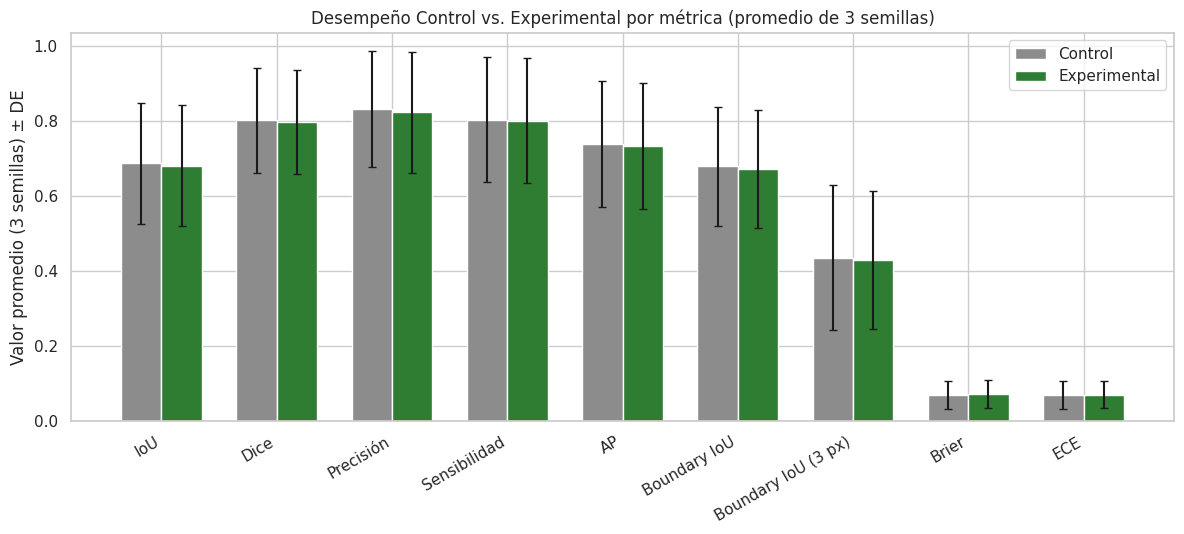

In [ ]:
FIG_DIR = CONFIG.output_root / "Figuras"
IDIOMAS = ("es",)          # ("es", "en") para generar también las figuras en inglés

I18N = {
    "es": {
        "seed": "Semilla", "seed_lc": "semilla", "metric": "Métrica", "source": "Fuente",
        "fig6_title": "Desempeño Control vs. Experimental por métrica (promedio de 3 semillas)",
        "fig6_ylabel": "Valor promedio (3 semillas) ± DE",
        "fig7_title": "Diferencia media (Experimental − Control) por métrica y semilla",
        "fig7_cbar": "Δ / DE(Control), orientado (verde = mejora)",
        "fig8_title": "Efecto del pipeline sobre Dice, por fuente y semilla",
        "fig8_ylabel": "ΔDice (Exp − Ctrl), IC 95 % bootstrap por clúster",
        "cols": ["Imagen + máscara real", "TP verde / FN rojo / FP azul", "Probabilidad (contorno real blanco)"],
        "tipo": {"mejora": "mayor mejora", "deterioro": "mayor deterioro", "especial": "lesión de interés"},
        "fig9_sub": {"a": "Caso de mejora", "b": "Caso de deterioro"},
        "metric_names": {"Sensibilidad": "Sensibilidad", "Precision": "Precisión", "BoundaryIoU": "Boundary IoU",
                         "BoundaryIoU_3px": "Boundary IoU (3 px)"},
    },
    "en": {
        "seed": "Seed", "seed_lc": "seed", "metric": "Metric", "source": "Source",
        "fig6_title": "Control vs. Experimental performance by metric (mean of 3 seeds)",
        "fig6_ylabel": "Mean value (3 seeds) ± SD",
        "fig7_title": "Mean difference (Experimental − Control) by metric and seed",
        "fig7_cbar": "Δ / SD(Control), oriented (green = improvement)",
        "fig8_title": "Pipeline effect on Dice, by source and seed",
        "fig8_ylabel": "ΔDice (Exp − Ctrl), 95% cluster-bootstrap CI",
        "cols": ["Image + ground-truth mask", "TP green / FN red / FP blue", "Probability (ground-truth contour in white)"],
        "tipo": {"mejora": "largest improvement", "deterioro": "largest deterioration", "especial": "lesion of interest"},
        "fig9_sub": {"a": "Improvement case", "b": "Deterioration case"},
        "metric_names": {"Sensibilidad": "Sensitivity", "Precision": "Precision", "BoundaryIoU": "Boundary IoU",
                         "BoundaryIoU_3px": "Boundary IoU (3 px)"},
    },
}

def etiqueta_metrica(m: str, lang: str) -> str:
    return I18N[lang]["metric_names"].get(m, m)

PALETA_GRUPOS = {"Control": "#8c8c8c", "Experimental": "#2e7d32"}
PALETA_FUENTES = {"DentalAI": "#1976d2", "Roboflow": "#f57c00"}

def guardar_fig(fig, nombre: str, lang: str) -> Path:
    ruta = FIG_DIR / f"{nombre}_{lang.upper()}.png"
    fig.savefig(ruta, dpi=200, bbox_inches="tight")
    return ruta

def fig6_desempeno(lang: str):
    T = I18N[lang]
    metricas = [m for m in CONFIG.metric_names if m not in ("HD95", "ASSD")]
    fig, ax = plt.subplots(figsize=(12, 5.5))
    ancho = 0.35
    x = np.arange(len(metricas))
    for off, grupo in ((-ancho / 2, "Control"), (ancho / 2, "Experimental")):
        sub = tabla_r1[tabla_r1["Grupo"] == grupo].set_index("Metrica").loc[metricas]
        ax.bar(x + off, sub["Media_promedio_semillas"], ancho, yerr=sub["DE_promedio_semillas"], capsize=3,
               color=PALETA_GRUPOS[grupo], label=grupo)
    ax.set_xticks(x); ax.set_xticklabels([etiqueta_metrica(m, lang) for m in metricas], rotation=30, ha="right")
    ax.set_ylabel(T["fig6_ylabel"]); ax.set_title(T["fig6_title"]); ax.legend()
    plt.tight_layout()
    guardar_fig(fig, "Fig6_desempeno_por_metrica", lang); plt.show()

for _l in IDIOMAS:
    fig6_desempeno(_l)

---
## 9. Inferencia pareada por semilla, con la imagen como clúster

Las lesiones de una misma fotografía no son independientes (70,5 % de las imágenes tienen más de una lesión). En cada semilla:

* **Por lesión**: `Delta_media`, media de las diferencias Experimental − Control.
* **Cluster-robustas**: bootstrap por clúster (se remuestrean imágenes completas), permutación de signos por imagen y modelo mixto con intercepto aleatorio por imagen. Además, t pareada, Wilcoxon, factor de Bayes (JZS), TOST y tamaño de efecto sobre la **diferencia media por imagen**.
* **Benjamini–Hochberg** sobre las métricas secundarias; Dice (primaria) no entra en la familia.
* **TOST**: el margen de equivalencia es empírico (ruido entre semillas del grupo Control, sección 9.1), no un umbral clínico.
* `p_wilcoxon_lesion_sin_cluster` trata las lesiones como independientes y se incluye solo como referencia; **no debe citarse**.

In [ ]:
def construir_diferencias_pareadas(df_semilla: pd.DataFrame, metrica: str) -> pd.DataFrame:
    """Pareo 1 a 1 por `lesion_id`; se conservan `stem` (clúster) y `fuente`."""
    c = df_semilla[df_semilla["grupo"] == "Control"][["lesion_id", "stem", "fuente", metrica]].rename(columns={metrica: "control"})
    e = df_semilla[df_semilla["grupo"] == "Experimental"][["lesion_id", metrica]].rename(columns={metrica: "experimental"})
    p = c.merge(e, on="lesion_id", how="inner", validate="one_to_one").dropna(subset=["control", "experimental"])
    p["diferencia"] = p["experimental"] - p["control"]
    return p.reset_index(drop=True)

def agregar_por_imagen(pareado: pd.DataFrame) -> pd.DataFrame:
    """Una fila por imagen (clúster): media de las lesiones de esa imagen."""
    return (pareado.groupby("stem")
            .agg(control=("control", "mean"), experimental=("experimental", "mean"),
                 diferencia=("diferencia", "mean"), n_lesiones=("diferencia", "size"), fuente=("fuente", "first"))
            .reset_index())

def bootstrap_cluster(pareado: pd.DataFrame, cfg: Phase5Config, rng: np.random.Generator) -> Dict[str, float]:
    """IC percentil 95 % remuestreando imágenes completas; estadístico = media de diferencias por lesión."""
    g = pareado.groupby("stem")["diferencia"].agg(["sum", "count"])
    sumas, cuentas = g["sum"].to_numpy(float), g["count"].to_numpy(float)
    n = len(g)
    idx = rng.integers(0, n, size=(cfg.bootstrap_n_resamples, n))
    est = sumas[idx].sum(axis=1) / cuentas[idx].sum(axis=1)
    lo, hi = np.percentile(est, [100 * cfg.alpha / 2, 100 * (1 - cfg.alpha / 2)])
    return {"boot_cluster_IC_inf": float(lo), "boot_cluster_IC_sup": float(hi)}

def permutacion_cluster(pareado: pd.DataFrame, cfg: Phase5Config, rng: np.random.Generator) -> Dict[str, float]:
    """Sign-flip por imagen (se invierte el signo de todas sus lesiones a la vez)."""
    g = pareado.groupby("stem")["diferencia"].agg(["sum", "count"])
    sumas, total = g["sum"].to_numpy(float), float(g["count"].sum())
    obs = sumas.sum() / total
    signos = rng.choice([-1.0, 1.0], size=(cfg.permutation_n_resamples, len(g)))
    nula = (signos * sumas[None, :]).sum(axis=1) / total
    p = (1 + np.sum(np.abs(nula) >= np.abs(obs) - 1e-15)) / (cfg.permutation_n_resamples + 1)
    return {"p_perm_cluster": float(p)}

def interpretar_bayes_factor(bf10: float) -> str:
    if bf10 > 100: return "evidencia extrema a favor de H1"
    if bf10 > 30: return "evidencia muy fuerte a favor de H1"
    if bf10 > 10: return "evidencia fuerte a favor de H1"
    if bf10 > 3: return "evidencia moderada a favor de H1"
    if bf10 > 1: return "evidencia anecdotica a favor de H1"
    if bf10 > 1 / 3: return "evidencia anecdotica a favor de H0"
    if bf10 > 1 / 10: return "evidencia moderada a favor de H0"
    return "evidencia fuerte o mayor a favor de H0"

def pruebas_por_imagen(img: pd.DataFrame, margen: float) -> Dict[str, float]:
    d = img["diferencia"].to_numpy(float)
    n = len(d)
    t, p_t = stats.ttest_rel(img["experimental"], img["control"])
    if np.all(d == 0):
        p_w = 1.0
    else:
        p_w = float(stats.wilcoxon(d, zero_method="wilcox", correction=True, method="approx").pvalue)
    n_mej, n_emp = int(np.sum(d > 0)), int(np.sum(d < 0))
    bf10 = float(pg.ttest(img["experimental"], img["control"], paired=True)["BF10"].values[0])
    se = d.std(ddof=1) / np.sqrt(n)
    if se > 0 and np.isfinite(margen) and margen > 0:
        p_tost = max(stats.t.sf((d.mean() + margen) / se, n - 1), stats.t.sf((margen - d.mean()) / se, n - 1))
    else:
        p_tost = np.nan
    return {"n_imagenes": n, "Delta_media_img": float(d.mean()), "p_t_img": float(p_t), "p_wilcoxon_img": p_w,
            "PS_img": (n_mej + 0.5 * (n - n_mej - n_emp)) / n, "cliffs_delta_img": (n_mej - n_emp) / n,
            "BF10_img": bf10, "BF01_img": 1 / bf10 if bf10 > 0 else np.nan, "interpretacion_BF10": interpretar_bayes_factor(bf10),
            "TOST_margen": margen, "TOST_p_img": float(p_tost) if np.isfinite(p_tost) else np.nan,
            "TOST_equivalente": bool(p_tost < CONFIG.alpha) if np.isfinite(p_tost) else False}

def mixto_interceptos(pareado: pd.DataFrame) -> Dict[str, float]:
    """Efecto por semilla con intercepto aleatorio de imagen (dependencia intra-imagen)."""
    try:
        aj = smf.mixedlm("diferencia ~ 1", data=pareado, groups="stem").fit(reml=True)
        ic = aj.conf_int().loc["Intercept"]
        return {"mixto_beta0": float(aj.params["Intercept"]), "mixto_IC_inf": float(ic[0]), "mixto_IC_sup": float(ic[1]),
                "mixto_p": float(aj.pvalues["Intercept"])}
    except Exception as e:
        print(f"Aviso: modelo mixto por semilla falló ({e}).")
        return {"mixto_beta0": np.nan, "mixto_IC_inf": np.nan, "mixto_IC_sup": np.nan, "mixto_p": np.nan}

def agregar_bh(df: pd.DataFrame, col_p: str, col_metrica: str, primaria: str, nueva: str, por: Optional[List[str]] = None) -> pd.DataFrame:
    """BH sobre las filas de métricas secundarias (la primaria queda NaN)."""
    df = df.copy(); df[nueva] = np.nan
    grupos = [df.index] if not por else [g.index for _, g in df.groupby(por)]
    for idx in grupos:
        sub = df.loc[idx]
        sec = sub[(sub[col_metrica] != primaria) & sub[col_p].notna()]
        if len(sec) > 0:
            df.loc[sec.index, nueva] = multipletests(sec[col_p].to_numpy(float), method="fdr_bh")[1]
    return df

### 9.1. Ruido entre semillas (Control vs. Control) y márgenes de equivalencia

Referencia de qué tan grande es "grande": cuánto cambia una misma condición al reentrenar con otra semilla. Se usa la media de |diferencia| de la media del Control sobre todos los pares de semillas. Se puede sobrescribir el margen con `margenes_equivalencia_manual` (por ejemplo `{"Dice": 0.02}`); vacío = ruido empírico.

In [ ]:
def ruido_entre_semillas(resultados: Dict[int, pd.DataFrame], cfg: Phase5Config) -> pd.DataFrame:
    """Para cada grupo y métrica: variación de la media entre semillas (todos los pares) y de la diferencia por lesión."""
    filas = []
    for grupo in cfg.groups:
        for metrica in cfg.metric_names:
            medias, por_semilla = {}, {}
            for s in cfg.seeds:
                x = resultados[s].query("grupo == @grupo")[["lesion_id", metrica]].rename(columns={metrica: f"v{s}"})
                por_semilla[s] = x; medias[s] = x[f"v{s}"].mean()
            dif_medias, de_lesion = [], []
            for si, sj in combinations(cfg.seeds, 2):
                m = por_semilla[si].merge(por_semilla[sj], on="lesion_id").dropna()
                dif_medias.append(abs(m[f"v{si}"].mean() - m[f"v{sj}"].mean()))
                de_lesion.append((m[f"v{si}"] - m[f"v{sj}"]).std(ddof=1))
            fila = {"grupo": grupo, "Metrica": metrica}
            fila.update({f"media_s{s}": medias[s] for s in cfg.seeds})
            fila.update({"abs_dif_media": float(np.mean(dif_medias)),
                         "max_abs_dif_media": float(np.max(dif_medias)),
                         "DE_medias_entre_semillas": float(np.std(list(medias.values()), ddof=1)),
                         "DE_dif_lesion_entre_semillas": float(np.mean(de_lesion))})
            filas.append(fila)
    return pd.DataFrame(filas)

tabla_ruido = ruido_entre_semillas(resultados_por_semilla, CONFIG)

margenes_equivalencia_manual: Dict[str, float] = {}      # ej.: {"Dice": 0.02}; vacío = usar el ruido empírico
MARGENES = {m: margenes_equivalencia_manual.get(m, float(tabla_ruido.query("grupo == 'Control' and Metrica == @m")["abs_dif_media"].iloc[0]))
            for m in CONFIG.metric_names}
print("Márgenes TOST (media de |dif. entre semillas| de la media del Control):", {k: round(v, 4) for k, v in MARGENES.items()})

Márgenes TOST (media de |dif. entre semillas| de la media del Control): {'IoU': 0.0016, 'Dice': 0.0013, 'Precision': 0.0016, 'Sensibilidad': 0.0009, 'AP': 0.0032, 'BoundaryIoU': 0.0016, 'BoundaryIoU_3px': 0.0032, 'HD95': 0.114, 'ASSD': 0.015, 'Brier': 0.0008, 'ECE': 0.0008}


### 9.2. Batería por semilla (Tabla 9)

In [ ]:
def bateria_por_semilla(df_semilla: pd.DataFrame, cfg: Phase5Config, seed: int) -> pd.DataFrame:
    rng = np.random.default_rng([cfg.stats_random_state, seed])
    filas = []
    for metrica in cfg.metric_names:
        par = construir_diferencias_pareadas(df_semilla, metrica)
        if par["stem"].nunique() < 5:
            continue
        img = agregar_por_imagen(par)
        fila = {"semilla": seed, "Metrica": metrica, "n_lesiones": len(par), "Delta_media": par["diferencia"].mean()}
        fila.update(bootstrap_cluster(par, cfg, rng))
        fila.update(permutacion_cluster(par, cfg, rng))
        fila.update(mixto_interceptos(par))
        fila.update(pruebas_por_imagen(img, MARGENES[metrica]))
        d = par["diferencia"].to_numpy(float)
        fila["p_wilcoxon_lesion_sin_cluster"] = 1.0 if np.all(d == 0) else float(
            stats.wilcoxon(d, zero_method="wilcox", correction=True, method="approx").pvalue)
        filas.append(fila)
    tabla = pd.DataFrame(filas)
    for col, nueva in (("p_perm_cluster", "p_perm_cluster_BH"), ("mixto_p", "mixto_p_BH"), ("p_wilcoxon_img", "p_wilcoxon_img_BH")):
        tabla = agregar_bh(tabla, col, "Metrica", cfg.metrica_primaria, nueva)
    return tabla

tablas_bateria = {seed: bateria_por_semilla(df_s, CONFIG, seed) for seed, df_s in resultados_por_semilla.items()}
tabla_bateria_total = pd.concat(tablas_bateria.values(), ignore_index=True)
tabla_bateria_total.to_csv(CONFIG.output_root / "Tablas" / "bateria_pareada_por_semilla.csv", index=False)

pd.set_option("display.float_format", lambda x: f"{x:0.4f}")
cols_vista = ["n_lesiones", "n_imagenes", "Delta_media", "boot_cluster_IC_inf", "boot_cluster_IC_sup",
              "p_perm_cluster", "p_perm_cluster_BH", "mixto_p", "p_wilcoxon_img", "PS_img", "BF10_img", "TOST_margen", "TOST_equivalente"]
display(tabla_bateria_total.set_index(["semilla", "Metrica"])[cols_vista])

n_lesiones  n_imagenes  Delta_media  \
semilla Metrica                                                
56      IoU                     564         156      -0.0054   
        Dice                    564         156      -0.0039   
        Precision               564         156      -0.0091   
        Sensibilidad            564         156      -0.0018   
        AP                      564         156      -0.0076   
        BoundaryIoU             564         156      -0.0057   
        BoundaryIoU_3px         564         156      -0.0037   
        HD95                    556         156      -0.1697   
        ASSD                    556         156      -0.0050   
        Brier                   564         156       0.0016   
        ECE                     564         156       0.0015   
42      IoU                     564         156      -0.0065   
        Dice                    564         156      -0.0039   
        Precision               564         156      -0.0069   
        Sensibilidad            564         156      -0.0035   
        AP                      564         156      -0.0082   
        BoundaryIoU             564         156      -0.0067   
        BoundaryIoU_3px         564         156      -0.0083   
        HD95                    560         156      -0.0313   
        ASSD                    560         156       0.0094   
        Brier                   564         156       0.0014   
        ECE                     564         156       0.0014   
25      IoU                     564         156      -0.0064   
        Dice                    564         156      -0.0049   
        Precision               564         156      -0.0082   
        Sensibilidad            564         156      -0.0036   
        AP                      564         156      -0.0029   
        BoundaryIoU             564         156      -0.0062   
        BoundaryIoU_3px         564         156      -0.0088   
        HD95                    559         156      -0.1110   
        ASSD                    559         156       0.0023   
        Brier                   564         156       0.0006   
        ECE                     564         156       0.0007   

                         boot_cluster_IC_inf  boot_cluster_IC_sup  \
semilla Metrica                                                     
56      IoU                          -0.0132               0.0019   
        Dice                         -0.0113               0.0031   
        Precision                    -0.0202               0.0003   
        Sensibilidad                 -0.0116               0.0081   
        AP                           -0.0149              -0.0004   
        BoundaryIoU                  -0.0135               0.0018   
        BoundaryIoU_3px              -0.0125               0.0051   
        HD95                         -0.9492               0.4394   
        ASSD                         -0.1222               0.1151   
        Brier                        -0.0003               0.0034   
        ECE                          -0.0005               0.0035   
42      IoU                          -0.0132               0.0004   
        Dice                         -0.0096               0.0018   
        Precision                    -0.0156               0.0008   
        Sensibilidad                 -0.0124               0.0060   
        AP                           -0.0155              -0.0007   
        BoundaryIoU                  -0.0134               0.0003   
        BoundaryIoU_3px              -0.0152              -0.0011   
        HD95                         -0.3903               0.3967   
        ASSD                         -0.0918               0.1318   
        Brier                        -0.0006               0.0033   
        ECE                          -0.0007               0.0033   
25      IoU                          -0.0130               0.0003   
        Dice                         -0.0111               

### 9.3. Fig. 7 — Mapa de calor de la diferencia media por métrica y semilla

El número impreso es la diferencia cruda (Δ) y el **color** es Δ / DE(Control) orientado (verde = mejora, también en HD95, ASSD, Brier y ECE), para que métricas en píxeles y en [0, 1] sean comparables.

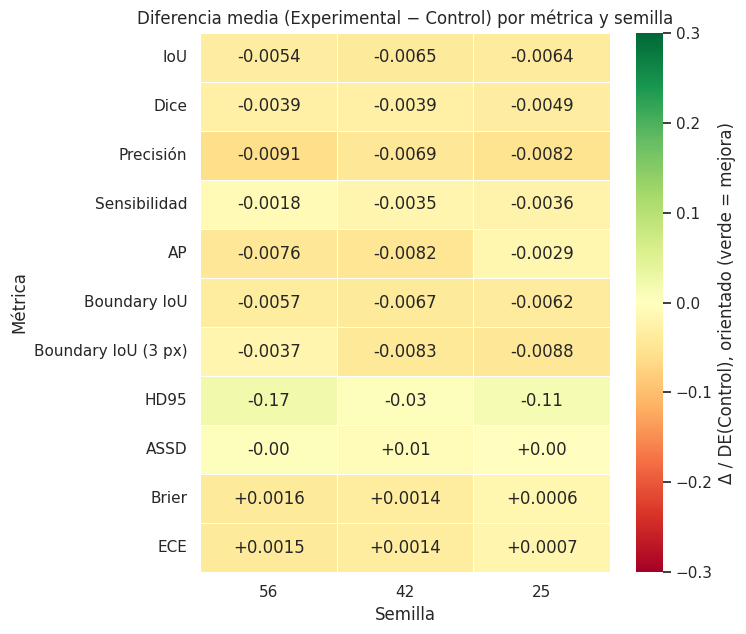

In [ ]:
def signo_orientado(metrica: str, valor: float) -> float:
    return valor if CONFIG.metrica_mayor_es_mejor[metrica] else -valor

def sd_control(metrica: str) -> float:
    return pd.concat([r.query("grupo == 'Control'")[metrica] for r in resultados_por_semilla.values()]).std(ddof=1)

def fig7_mapa_calor(lang: str):
    T = I18N[lang]
    metricas = list(CONFIG.metric_names)
    delta = pd.DataFrame({m: {s: tablas_bateria[s].set_index("Metrica").loc[m, "Delta_media"] for s in CONFIG.seeds}
                          for m in metricas}).T[list(CONFIG.seeds)]
    color = pd.DataFrame({s: {m: signo_orientado(m, delta.loc[m, s]) / sd_control(m) for m in metricas} for s in CONFIG.seeds})
    anot = delta.copy().astype(object)
    for m in metricas:
        fmt = "{:+.2f}" if m in ("HD95", "ASSD") else "{:+.4f}"
        for s in CONFIG.seeds:
            anot.loc[m, s] = fmt.format(delta.loc[m, s])
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    sns.heatmap(color.values, cmap="RdYlGn", center=0, vmin=-0.3, vmax=0.3, annot=anot.values, fmt="",
                linewidths=.5, ax=ax, cbar_kws={"label": T["fig7_cbar"]},
                xticklabels=[f"{s}" for s in CONFIG.seeds], yticklabels=[etiqueta_metrica(m, lang) for m in metricas])
    ax.set_xlabel(T["seed"]); ax.set_ylabel(T["metric"]); ax.set_title(T["fig7_title"])
    plt.tight_layout()
    guardar_fig(fig, "Fig7_mapa_calor_diferencia_media", lang); plt.show()

for _l in IDIOMAS:
    fig7_mapa_calor(_l)

---
## 10. Modelo de efectos mixtos sobre todas las semillas (Ecuaciones 1 y 2; Tabla 8)

Sea `D_ims = Y_Experimental − Y_Control` para la lesión *i*, de la imagen *m*, bajo la semilla *s*. Con REML e intercepto aleatorio por imagen:

* **Modelo primario (Ec. 1, codificación suma)**: `D ~ C(semilla, Sum) + C(fuente, Sum)`. `β0` es el efecto medio del pipeline promediado sobre semillas y fuentes.
* **Comparación (codificación tratamiento)**: `β0` es el efecto en la semilla 42 y DentalAI.
* **Sensibilidad con lesión**: componente de varianza adicional por lesión (cada lesión se mide bajo las tres semillas).
* **Modelo de celdas (Ec. 2)**: `D ~ 0 + C(semilla×fuente)`, con efectos por semilla y fuente, contrastes entre pares de semillas y dos pruebas de Wald conjuntas (S−1 gl): `heterogeneidad_semillas` e `interaccion_semilla_x_fuente`.

Con solo tres semillas, la semilla se trata como efecto fijo.

In [ ]:
def construir_tabla_larga(resultados: Dict[int, pd.DataFrame], metrica: str) -> pd.DataFrame:
    piezas = []
    for seed, df in resultados.items():
        p = construir_diferencias_pareadas(df, metrica).assign(semilla=seed)
        piezas.append(p[["lesion_id", "stem", "fuente", "semilla", "diferencia"]])
    largo = pd.concat(piezas, ignore_index=True)
    largo["celda"] = largo["semilla"].astype(str) + "_" + largo["fuente"]
    return largo

def contraste_fe(ajuste, pesos: Dict[str, float]) -> Dict[str, float]:
    """Contraste lineal de efectos fijos con Wald (z)."""
    fe = ajuste.fe_params
    cov = ajuste.cov_params().loc[fe.index, fe.index].to_numpy(float)
    w = np.array([pesos.get(k, 0.0) for k in fe.index], dtype=float)
    est = float(w @ fe.to_numpy(float)); se = float(np.sqrt(w @ cov @ w))
    z = est / se if se > 0 else np.nan
    return {"est": est, "se": se, "inf": est - 1.959964 * se, "sup": est + 1.959964 * se,
            "p": float(2 * (1 - stats.norm.cdf(abs(z)))) if np.isfinite(z) else np.nan}

def wald_conjunto(ajuste, filas: List[Dict[str, float]]) -> Tuple[float, int, float]:
    """Prueba de Wald conjunta H0: L·beta = 0 (cada fila de L es un contraste); devuelve (chi2, gl, p)."""
    fe = ajuste.fe_params
    cov = ajuste.cov_params().loc[fe.index, fe.index].to_numpy(float)
    L = np.array([[fila.get(k, 0.0) for k in fe.index] for fila in filas], dtype=float)
    Lb = L @ fe.to_numpy(float)
    chi2 = float(Lb @ np.linalg.solve(L @ cov @ L.T, Lb))
    gl = L.shape[0]
    return chi2, gl, float(stats.chi2.sf(chi2, gl))

def ajustar_mixto(formula: str, data: pd.DataFrame, con_lesion: bool = False):
    if con_lesion:
        mod = smf.mixedlm(formula, data, groups="stem", re_formula="1", vc_formula={"lesion": "0 + C(lesion_id)"})
    else:
        mod = smf.mixedlm(formula, data, groups="stem")
    return mod.fit(reml=True)

def modelos_mixtos_metrica(df_largo: pd.DataFrame, cfg: Phase5Config) -> Dict[str, float]:
    out: Dict[str, float] = {"n_obs": len(df_largo)}
    # --- primario (suma)
    a = ajustar_mixto("diferencia ~ C(semilla, Sum) + C(fuente, Sum)", df_largo)
    ic = a.conf_int().loc["Intercept"]
    out.update({"beta0_suma": float(a.params["Intercept"]), "beta0_suma_IC_inf": float(ic[0]), "beta0_suma_IC_sup": float(ic[1]),
                "beta0_suma_p": float(a.pvalues["Intercept"]),
                "var_imagen": float(a.cov_re.iloc[0, 0]), "var_residual": float(a.scale)})
    # --- tratamiento
    try:
        t = ajustar_mixto("diferencia ~ C(semilla) + C(fuente)", df_largo)
        out.update({"beta0_tratamiento": float(t.params["Intercept"]), "beta0_tratamiento_p": float(t.pvalues["Intercept"])})
    except Exception as e:
        print(f"Aviso (tratamiento): {e}")
    # --- sensibilidad con varianza de lesión
    try:
        v = ajustar_mixto("diferencia ~ C(semilla, Sum) + C(fuente, Sum)", df_largo, con_lesion=True)
        icv = v.conf_int().loc["Intercept"]
        out.update({"beta0_con_lesion": float(v.params["Intercept"]), "beta0_con_lesion_IC_inf": float(icv[0]),
                    "beta0_con_lesion_IC_sup": float(icv[1]), "beta0_con_lesion_p": float(v.pvalues["Intercept"])})
    except Exception as e:
        print(f"Aviso (sensibilidad con lesión): {e}")
    # --- celdas semilla x fuente
    c = ajustar_mixto("diferencia ~ 0 + C(celda)", df_largo)
    seeds, fuentes = list(cfg.seeds), ["DentalAI", "Roboflow"]
    S = len(seeds); f1, f2 = fuentes
    nom = lambda s_, f_: f"C(celda)[{s_}_{f_}]"
    for s_ in seeds:
        for f_ in fuentes:
            r = contraste_fe(c, {nom(s_, f_): 1.0})
            out[f"celda_{s_}_{f_}"] = r["est"]; out[f"celda_{s_}_{f_}_IC_inf"] = r["inf"]
            out[f"celda_{s_}_{f_}_IC_sup"] = r["sup"]; out[f"celda_{s_}_{f_}_p"] = r["p"]
    def combinar(pesos: Dict[Tuple[int, str], float], etiqueta: str):
        r = contraste_fe(c, {nom(s_, f_): w for (s_, f_), w in pesos.items()})
        out[etiqueta] = r["est"]; out[etiqueta + "_IC_inf"] = r["inf"]; out[etiqueta + "_IC_sup"] = r["sup"]; out[etiqueta + "_p"] = r["p"]
    for s_ in seeds:
        combinar({(s_, f1): .5, (s_, f2): .5}, f"efecto_semilla{s_}")
    for f_ in fuentes:
        combinar({(s_, f_): 1.0 / S for s_ in seeds}, f"efecto_{f_}")
    combinar({**{(s_, f1): 1.0 / S for s_ in seeds}, **{(s_, f2): -1.0 / S for s_ in seeds}}, "dif_entre_fuentes")
    combinar({(s_, f_): 1.0 / (2 * S) for s_ in seeds for f_ in fuentes}, "efecto_medio_celdas")
    for si, sj in combinations(seeds, 2):
        combinar({(si, f1): .5, (si, f2): .5, (sj, f1): -.5, (sj, f2): -.5}, f"het_s{si}_vs_s{sj}")
    # pruebas conjuntas (Wald, S-1 gl)
    filas_het = [{nom(s_, f1): .5, nom(s_, f2): .5, nom(seeds[-1], f1): -.5, nom(seeds[-1], f2): -.5} for s_ in seeds[:-1]]
    filas_int = [{nom(s_, f1): 1.0, nom(s_, f2): -1.0, nom(seeds[-1], f1): -1.0, nom(seeds[-1], f2): 1.0} for s_ in seeds[:-1]]
    for etiqueta, filas_l in (("heterogeneidad_semillas", filas_het), ("interaccion_semilla_x_fuente", filas_int)):
        chi2, gl, p = wald_conjunto(c, filas_l)
        out[etiqueta + "_chi2"] = chi2; out[etiqueta + "_gl"] = gl; out[etiqueta + "_p"] = p
    return out

def ajustar_todos_los_mixtos(resultados: Dict[int, pd.DataFrame], cfg: Phase5Config, metricas: Tuple[str, ...]) -> pd.DataFrame:
    filas = []
    for metrica in metricas:
        try:
            r = modelos_mixtos_metrica(construir_tabla_larga(resultados, metrica), cfg)
            r["Metrica"] = metrica
            filas.append(r)
        except Exception as e:
            print(f"Aviso: modelos mixtos fallaron para {metrica}: {e}")
    df = pd.DataFrame(filas)
    for col in ("beta0_suma_p", "heterogeneidad_semillas_p", "interaccion_semilla_x_fuente_p", "dif_entre_fuentes_p"):
        df = agregar_bh(df, col, "Metrica", cfg.metrica_primaria, col + "_BH")
    return df.set_index("Metrica")

In [ ]:
tabla_mixto = ajustar_todos_los_mixtos(resultados_por_semilla, CONFIG, CONFIG.metric_names)
tabla_mixto.to_csv(CONFIG.output_root / "Tablas" / "modelo_mixto_semillas.csv")

pd.set_option("display.float_format", lambda x: f"{x:0.4f}")
print("Efecto medio del pipeline (codificación suma), comparación con codificación tratamiento y con varianza de lesión (Tabla 8):")
display(tabla_mixto[["n_obs", "beta0_suma", "beta0_suma_IC_inf", "beta0_suma_IC_sup", "beta0_suma_p", "beta0_suma_p_BH",
                     "beta0_tratamiento", "beta0_con_lesion", "beta0_con_lesion_p", "var_imagen", "var_residual"]])
print("\nHeterogeneidad entre semillas (Wald conjunto) e interacción semilla x fuente:")
display(tabla_mixto[[f"efecto_semilla{s_}" for s_ in CONFIG.seeds] +
                    ["heterogeneidad_semillas_chi2", "heterogeneidad_semillas_gl", "heterogeneidad_semillas_p", "heterogeneidad_semillas_p_BH",
                     "interaccion_semilla_x_fuente_chi2", "interaccion_semilla_x_fuente_p", "interaccion_semilla_x_fuente_p_BH"]])

Efecto medio del pipeline (codificación suma), comparación con codificación tratamiento y con varianza de lesión (Tabla 8):


,n_obs,beta0_suma,beta0_suma_IC_inf,beta0_suma_IC_sup,beta0_suma_p,beta0_suma_p_BH,beta0_tratamiento,beta0_con_lesion,beta0_con_lesion_p,var_imagen,var_residual
Metrica,,,,,,,,,,,
IoU,1692,-0.0043,-0.0104,0.0018,0.1658,0.4432,-0.0076,-0.0056,0.0563,0.0006,0.0068
Dice,1692,-0.0031,-0.0097,0.0035,0.3576,NaN,-0.0067,-0.0038,0.1502,0.0010,0.0059
Precision,1692,-0.0059,-0.0146,0.0027,0.1773,0.4432,-0.0145,-0.0068,0.0456,0.0016,0.0100
Sensibilidad,1692,-0.0025,-0.0098,0.0049,0.5135,0.7049,-0.0026,-0.0026,0.5285,0.0009,0.0105
AP,1692,-0.0042,-0.0113,0.0029,0.2418,0.4836,-0.0044,-0.0056,0.0733,0.0010,0.0080
BoundaryIoU,1692,-0.0048,-0.0101,0.0006,0.0797,0.4432,-0.0070,-0.0058,0.0560,0.0003,0.0072
BoundaryIoU_3px,1692,-0.0053,-0.0118,0.0012,0.1122,0.4432,-0.0093,-0.0067,0.0352,0.0007,0.0080
HD95,1675,0.1574,-0.7735,1.0882,0.7404,0.7404,-0.0130,0.1190,0.7854,30.2896,26.1366
ASSD,1675,0.0831,-0.2142,0.3803,0.5839,0.7049,-0.0010,0.0775,0.5945,3.4020,0.6805



Heterogeneidad entre semillas (Wald conjunto) e interacción semilla x fuente:


,efecto_semilla56,efecto_semilla42,efecto_semilla25,heterogeneidad_semillas_chi2,heterogeneidad_semillas_gl,heterogeneidad_semillas_p,heterogeneidad_semillas_p_BH,interaccion_semilla_x_fuente_chi2,interaccion_semilla_x_fuente_p,interaccion_semilla_x_fuente_p_BH
Metrica,,,,,,,,,,
IoU,-0.0040,-0.0047,-0.0043,0.0212,2,0.9895,0.9895,0.3892,0.8231,0.9427
Dice,-0.0030,-0.0029,-0.0035,0.0165,2,0.9918,NaN,0.2725,0.8726,NaN
Precision,-0.0070,-0.0045,-0.0063,0.1703,2,0.9184,0.9895,0.1180,0.9427,0.9427
Sensibilidad,-0.0016,-0.0033,-0.0024,0.0675,2,0.9668,0.9895,0.6773,0.7127,0.9427
AP,-0.0060,-0.0058,-0.0009,1.1409,2,0.5653,0.9895,0.4383,0.8032,0.9427
BoundaryIoU,-0.0047,-0.0053,-0.0043,0.0388,2,0.9808,0.9895,0.6378,0.7269,0.9427
BoundaryIoU_3px,-0.0023,-0.0068,-0.0066,0.8667,2,0.6483,0.9895,0.6154,0.7351,0.9427
HD95,0.0779,0.2420,0.1522,0.2758,2,0.8712,0.9895,0.1828,0.9127,0.9427
ASSD,0.0775,0.0908,0.0809,0.0747,2,0.9633,0.9895,0.1212,0.9412,0.9427


### 10.1. Sensibilidad de HD95/ASSD a las predicciones vacías

Los contornos vacíos se excluyen de HD95/ASSD (ocurren en los peores casos). Se repite el modelo primario con la versión penalizada (valor = diagonal del lienzo) para verificar si la conclusión cambia.

In [ ]:
def mixtos_sensibilidad_penalizada(resultados: Dict[int, pd.DataFrame], cfg: Phase5Config) -> pd.DataFrame:
    filas = []
    for metrica in ("HD95_pen", "ASSD_pen"):
        largo = construir_tabla_larga(resultados, metrica)
        a = ajustar_mixto("diferencia ~ C(semilla, Sum) + C(fuente, Sum)", largo)
        ic = a.conf_int().loc["Intercept"]
        filas.append({"Metrica": metrica, "n_obs": len(largo), "beta0_suma": a.params["Intercept"],
                      "IC_inf": ic[0], "IC_sup": ic[1], "p": a.pvalues["Intercept"]})
    return pd.DataFrame(filas).set_index("Metrica")

tabla_sens_pen = mixtos_sensibilidad_penalizada(resultados_por_semilla, CONFIG)
display(tabla_sens_pen)

,n_obs,beta0_suma,IC_inf,IC_sup,p
Metrica,,,,,
HD95_pen,1692,4.5642,-6.0005,15.1290,0.3971
ASSD_pen,1692,4.5778,-6.0233,15.1789,0.3974


### 10.2. Reproducibilidad entre semillas

Tres criterios complementarios (ninguno basta por sí solo; con 3 semillas la coincidencia de signo ocurre por azar con probabilidad 25 %):

1. **Signo y magnitud orientados** (positivo = el pipeline mejora, también en métricas donde menor es mejor).
2. **Concordancia del efecto por lesión e imagen** entre pares de semillas (Spearman) e ICC(3,1) por imagen.
3. **Efecto frente a ruido**: |β0| dividido por el ruido entre semillas del Control.

In [ ]:
def icc_consistencia(X: np.ndarray) -> float:
    """ICC(3,1) (consistencia, evaluador fijo, medida única) por ANOVA de dos vías; X es (n_sujetos, k_semillas)."""
    n, k = X.shape
    gm = X.mean()
    ss_filas = k * np.sum((X.mean(axis=1) - gm) ** 2)
    ss_cols = n * np.sum((X.mean(axis=0) - gm) ** 2)
    ss_err = np.sum((X - gm) ** 2) - ss_filas - ss_cols
    ms_f, ms_e = ss_filas / (n - 1), ss_err / ((n - 1) * (k - 1))
    return float((ms_f - ms_e) / (ms_f + (k - 1) * ms_e))

def tabla_reproducibilidad(resultados: Dict[int, pd.DataFrame], tmix: pd.DataFrame, ruido: pd.DataFrame, cfg: Phase5Config) -> pd.DataFrame:
    filas = []
    for metrica in cfg.metric_names:
        base = None
        for s_ in cfg.seeds:
            d = construir_diferencias_pareadas(resultados[s_], metrica)[["lesion_id", "stem", "diferencia"]].rename(columns={"diferencia": f"d{s_}"})
            base = d if base is None else base.merge(d[["lesion_id", f"d{s_}"]], on="lesion_id")
        w = base.dropna()
        wi = w.groupby("stem")[[f"d{s_}" for s_ in cfg.seeds]].mean()
        efectos = {s_: signo_orientado(metrica, w[f"d{s_}"].mean()) for s_ in cfg.seeds}
        rhos_img, rhos_les = [], []
        for si, sj in combinations(cfg.seeds, 2):
            r_l, _ = stats.spearmanr(w[f"d{si}"], w[f"d{sj}"]); r_i, _ = stats.spearmanr(wi[f"d{si}"], wi[f"d{sj}"])
            rhos_les.append(r_l); rhos_img.append(r_i)
        icc3 = icc_consistencia(wi.to_numpy(float))
        ruido_c = float(ruido.query("grupo == 'Control' and Metrica == @metrica")["abs_dif_media"].iloc[0])
        beta = float(tmix.loc[metrica, "beta0_suma"]) if metrica in tmix.index else np.nan
        signos = np.sign(list(efectos.values()))
        fila = {"Metrica": metrica}
        fila.update({f"efecto_orientado_s{s_}": efectos[s_] for s_ in cfg.seeds})
        fila.update({"mismo_signo_todas": bool(np.all(signos == signos[0]) and signos[0] != 0), "n_lesiones": len(w), "n_imagenes": len(wi),
                     "spearman_lesion_medio": float(np.mean(rhos_les)), "spearman_imagen_medio": float(np.mean(rhos_img)),
                     "spearman_imagen_min": float(np.min(rhos_img)), "ICC3_imagen": icc3,
                     "abs_beta0_suma": abs(beta), "ruido_entre_semillas_Control": ruido_c,
                     "razon_efecto_ruido": abs(beta) / ruido_c if ruido_c > 0 else np.nan})
        filas.append(fila)
    return pd.DataFrame(filas).set_index("Metrica")

tabla_repro = tabla_reproducibilidad(resultados_por_semilla, tabla_mixto, tabla_ruido, CONFIG)
tabla_repro.to_csv(CONFIG.output_root / "Tablas" / "reproducibilidad_entre_semillas.csv")
pd.set_option("display.float_format", lambda x: f"{x:0.4f}")
display(tabla_repro)

,efecto_orientado_s56,efecto_orientado_s42,efecto_orientado_s25,mismo_signo_todas,n_lesiones,n_imagenes,spearman_lesion_medio,spearman_imagen_medio,spearman_imagen_min,ICC3_imagen,abs_beta0_suma,ruido_entre_semillas_Control,razon_efecto_ruido
Metrica,,,,,,,,,,,,,
IoU,-0.0054,-0.0065,-0.0064,True,564,156,0.4443,0.4946,0.4628,0.4756,0.0043,0.0016,2.6667
Dice,-0.0039,-0.0039,-0.0049,True,564,156,0.4378,0.4803,0.4314,0.4047,0.0031,0.0013,2.3220
Precision,-0.0091,-0.0069,-0.0082,True,564,156,0.3826,0.4294,0.3763,0.3451,0.0059,0.0016,3.8215
Sensibilidad,-0.0018,-0.0035,-0.0036,True,564,156,0.4548,0.4988,0.4735,0.4855,0.0025,0.0009,2.8108
AP,-0.0076,-0.0082,-0.0029,True,564,156,0.4094,0.3973,0.3515,0.4280,0.0042,0.0032,1.3200
BoundaryIoU,-0.0057,-0.0067,-0.0062,True,564,156,0.4466,0.4942,0.4444,0.5555,0.0048,0.0016,3.0410
BoundaryIoU_3px,-0.0037,-0.0083,-0.0088,True,564,156,0.4355,0.4542,0.4227,0.4625,0.0053,0.0032,1.6649
HD95,0.1725,0.0290,0.1108,True,554,156,0.4090,0.4390,0.3979,0.8871,0.1574,0.1140,1.3809
ASSD,0.0062,-0.0109,-0.0013,False,554,156,0.4356,0.4688,0.4267,0.9485,0.0831,0.0150,5.5293


### 10.3. Calibración por clase de píxel (Tabla 7)

Resumen de `DefConf_pos`, `DefBrier_pos`, `ConfFondo_neg` y `BrierFondo_neg` (promedio de las tres semillas, por grupo) y efecto medio del pipeline según el modelo mixto de codificación suma. Recordatorio: `DefConf_pos` y `DefBrier_pos` miden déficit de confianza en la lesión, no errores de calibración.

In [ ]:
metricas_calib = ("DefConf_pos", "DefBrier_pos", "ConfFondo_neg", "BrierFondo_neg")
desc_calib = pd.concat([tabla_descriptiva(df, CONFIG, metricas_calib).assign(semilla=s) for s, df in resultados_por_semilla.items()])
prom_calib = (desc_calib.groupby(["Metrica", "Grupo"])["Media"].mean().unstack("Grupo")
              .rename(columns={"Control": "Media_Control", "Experimental": "Media_Experimental"}))
mixto_calib = ajustar_todos_los_mixtos(resultados_por_semilla, CONFIG, metricas_calib)[
    ["n_obs", "beta0_suma", "beta0_suma_IC_inf", "beta0_suma_IC_sup", "beta0_suma_p"]]
tabla_calibracion = prom_calib.join(mixto_calib).loc[list(metricas_calib)]
tabla_calibracion.to_csv(CONFIG.output_root / "Tablas" / "calibracion_por_clase.csv")
display(tabla_calibracion)

,Media_Control,Media_Experimental,n_obs,beta0_suma,beta0_suma_IC_inf,beta0_suma_IC_sup,beta0_suma_p
Metrica,,,,,,,
DefConf_pos,0.1995,0.2023,1692,0.0024,-0.0049,0.0096,0.5237
DefBrier_pos,0.1882,0.1910,1692,0.0024,-0.0048,0.0097,0.5094
ConfFondo_neg,0.0465,0.0469,1692,-0.0007,-0.0029,0.0015,0.5263
BrierFondo_neg,0.0428,0.0433,1692,-0.0006,-0.0027,0.0015,0.5636


---
## 11. Desempeño por fuente (Tabla 10, Fig. 8)

Se estratifica por semilla × fuente con bootstrap por clúster, permutación por clúster y Wilcoxon sobre medias por imagen. Los contrastes formales (diferencia entre fuentes e interacción semilla × fuente) están en la sección 10. La corrección BH se aplica sobre la familia exploratoria semilla × fuente × métrica secundaria.

In [ ]:
METRICAS_POR_FUENTE = ("Dice", "IoU", "BoundaryIoU_3px", "HD95", "ASSD", "AP")

def bateria_por_estrato(resultados: Dict[int, pd.DataFrame], cfg: Phase5Config) -> pd.DataFrame:
    filas = []
    for seed, df in resultados.items():
        rng = np.random.default_rng([cfg.stats_random_state, seed, 7])
        for fuente in sorted(df["fuente"].unique()):
            dfx = df[df["fuente"] == fuente]
            for metrica in METRICAS_POR_FUENTE:
                par = construir_diferencias_pareadas(dfx, metrica)
                if par["stem"].nunique() < 5:
                    continue
                img = agregar_por_imagen(par)
                d = img["diferencia"].to_numpy(float)
                fila = {"semilla": seed, "fuente": fuente, "Metrica": metrica, "n_lesiones": len(par), "n_imagenes": len(img),
                        "Delta_media": par["diferencia"].mean(),
                        "p_wilcoxon_img": 1.0 if np.all(d == 0) else float(stats.wilcoxon(d, zero_method="wilcox", correction=True, method="approx").pvalue),
                        "PS_img": (np.sum(d > 0) + 0.5 * np.sum(d == 0)) / len(d)}
                fila.update(bootstrap_cluster(par, cfg, rng)); fila.update(permutacion_cluster(par, cfg, rng))
                filas.append(fila)
    t = pd.DataFrame(filas)
    return agregar_bh(t, "p_perm_cluster", "Metrica", cfg.metrica_primaria, "p_perm_cluster_BH_familia")

tabla_por_fuente = bateria_por_estrato(resultados_por_semilla, CONFIG)
tabla_por_fuente.to_csv(CONFIG.output_root / "Tablas" / "desempeno_por_fuente_semilla.csv", index=False)
pd.set_option("display.float_format", lambda x: f"{x:0.4f}")
display(tabla_por_fuente.set_index(["Metrica", "fuente", "semilla"])[
    ["n_lesiones", "n_imagenes", "Delta_media", "boot_cluster_IC_inf", "boot_cluster_IC_sup", "p_perm_cluster", "p_perm_cluster_BH_familia", "PS_img"]])

,,,n_lesiones,n_imagenes,Delta_media,boot_cluster_IC_inf,boot_cluster_IC_sup,p_perm_cluster,p_perm_cluster_BH_familia,PS_img
Metrica,fuente,semilla,,,,,,,,
Dice,DentalAI,56,342,89,-0.0047,-0.0164,0.0058,0.4127,NaN,0.4494
IoU,DentalAI,56,342,89,-0.0061,-0.0174,0.0050,0.2988,0.8522,0.4607
BoundaryIoU_3px,DentalAI,56,342,89,-0.0034,-0.0165,0.0089,0.6063,0.9573,0.5169
HD95,DentalAI,56,334,89,-0.0470,-0.2136,0.1195,0.6035,0.9573,0.4775
ASSD,DentalAI,56,334,89,-0.0181,-0.0606,0.0246,0.4390,0.8985,0.5281
AP,DentalAI,56,342,89,-0.0084,-0.0188,0.0021,0.1296,0.5964,0.4213
Dice,Roboflow,56,222,67,-0.0027,-0.0090,0.0040,0.4190,NaN,0.4627
IoU,Roboflow,56,222,67,-0.0045,-0.0126,0.0038,0.3076,0.8522,0.4776
BoundaryIoU_3px,Roboflow,56,222,67,-0.0042,-0.0150,0.0073,0.4792,0.8985,0.4627


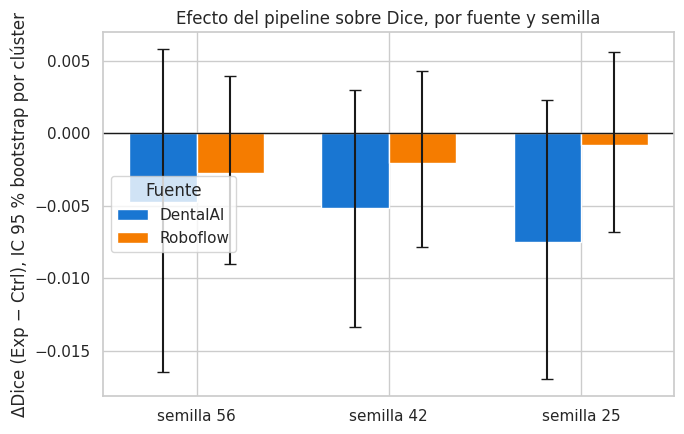

In [ ]:
def fig8_dice_por_fuente(lang: str):
    T = I18N[lang]
    sub = tabla_por_fuente.query("Metrica == 'Dice'")
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ancho = 0.35
    seeds_ord = list(CONFIG.seeds)
    for k, fuente in enumerate(sorted(sub["fuente"].unique())):
        g = sub[sub["fuente"] == fuente].set_index("semilla").loc[seeds_ord]
        x = np.arange(len(g)) + (k - 0.5) * ancho
        ax.bar(x, g["Delta_media"], ancho, color=PALETA_FUENTES.get(fuente, "gray"), label=fuente,
               yerr=[g["Delta_media"] - g["boot_cluster_IC_inf"], g["boot_cluster_IC_sup"] - g["Delta_media"]], capsize=4)
    ax.set_xticks(np.arange(len(seeds_ord))); ax.set_xticklabels([f"{T['seed_lc']} {s}" for s in seeds_ord])
    ax.axhline(0, color="k", lw=1); ax.set_ylabel(T["fig8_ylabel"]); ax.legend(title=T["source"]); ax.set_title(T["fig8_title"])
    plt.tight_layout()
    guardar_fig(fig, "Fig8_dice_por_fuente_y_semilla", lang); plt.show()

for _l in IDIOMAS:
    fig8_dice_por_fuente(_l)

---
## 12. Análisis cualitativo (Fig. 9)

La Fig. 9 muestra dos lesiones del grupo Experimental, una con mejora y otra con deterioro en Dice. Se fijan explícitamente en `CASOS_FIG9` (identificador y semilla) para que la figura sea reproducible:

* **(a)** `roboflow_5f8677374f#0`, semilla 42 (lesión de interés, mejora).
* **(b)** `dentalai_ee5d10fa4d#1`, semilla 25 (mayor deterioro de Dice en esa semilla).

Cada panel muestra, con zoom sobre la lesión: imagen con contorno real, mapa TP/FN/FP (verde/rojo/azul) y probabilidad predicha con el contorno real en blanco. Si cambian los checkpoints, las lesiones deben volver a elegirse (los valores de ΔDice se imprimen para verificarlo).

(a) roboflow_5f8677374f#0 semilla 42: Dice Control=0.735, Experimental=0.926, ΔDice=+0.191
(b) dentalai_ee5d10fa4d#1 semilla 25: Dice Control=0.400, Experimental=0.154, ΔDice=-0.246
[semilla=25, grupo=Control] sam2_control_s25_20261003_055906_final_ema.pt (época 80, val_dice=0.8075) | cambio decodificador=4.94e-02
[semilla=25, grupo=Experimental] sam2_experimental_s25_20261015_191732_final_ema.pt (época 80, val_dice=0.7955) | cambio decodificador=5.10e-02
[semilla=42, grupo=Control] sam2_control_s42_20261002_033006_final_ema.pt (época 80, val_dice=0.8077) | cambio decodificador=5.39e-02
[semilla=42, grupo=Experimental] sam2_experimental_s42_20261002_214552_final_ema.pt (época 80, val_dice=0.7971) | cambio decodificador=5.06e-02


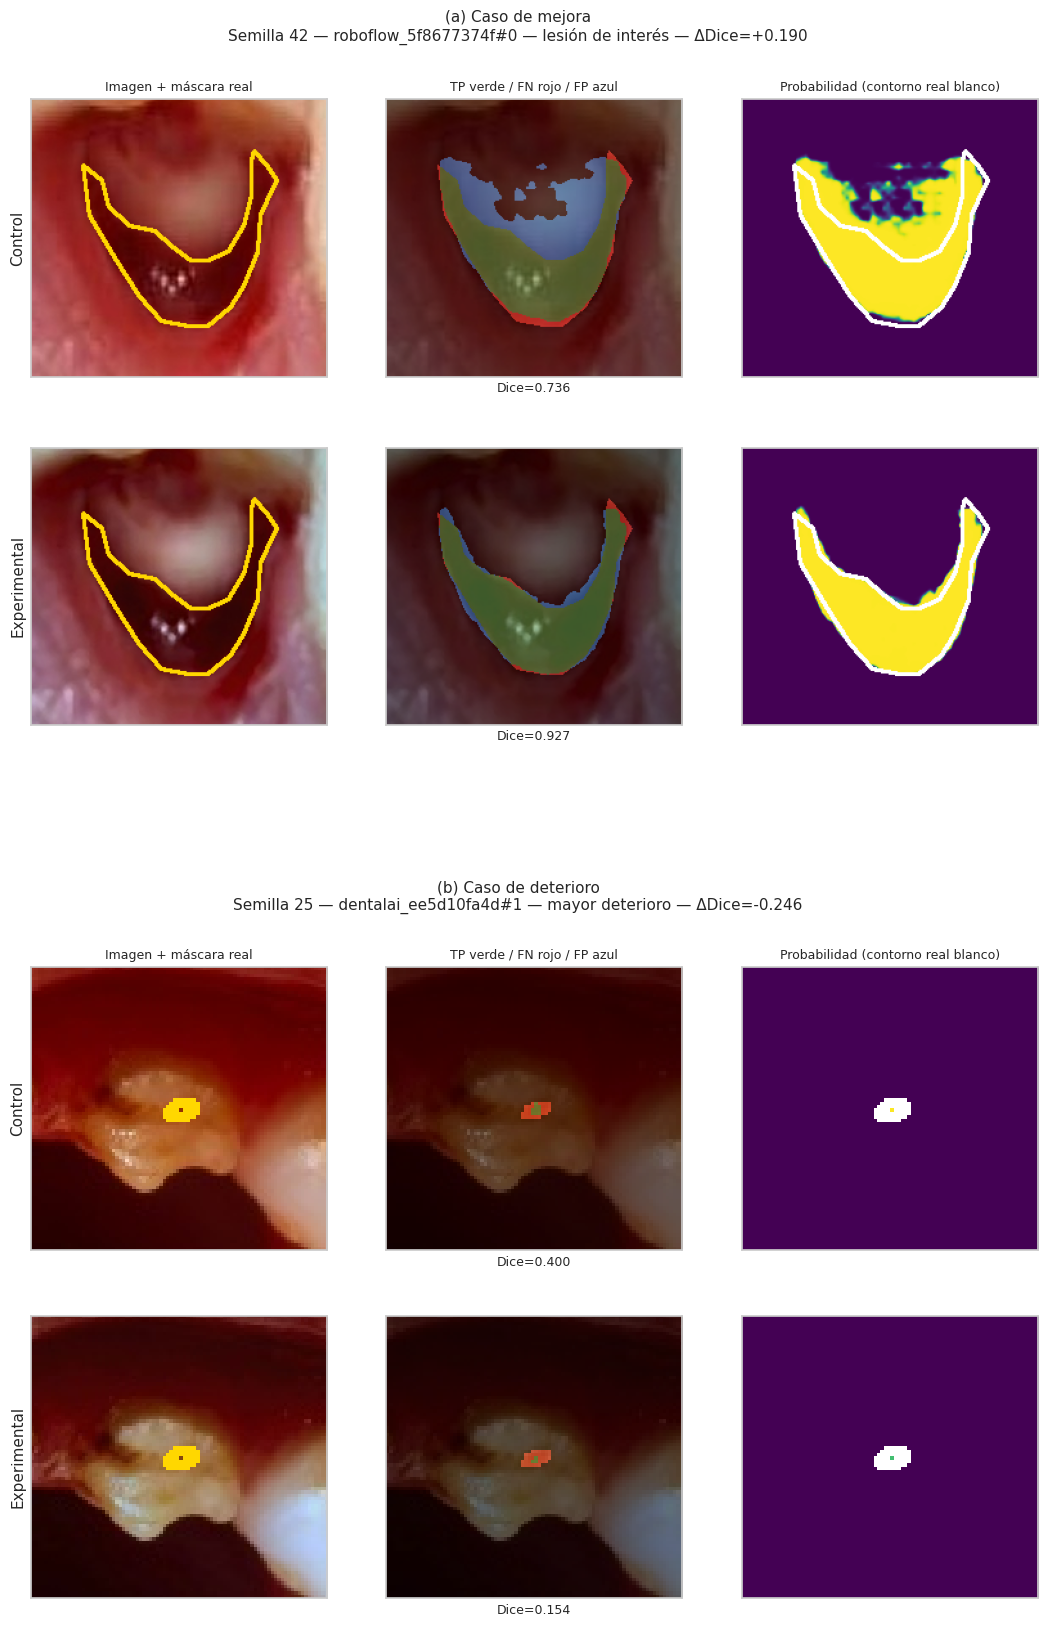

In [ ]:
CASOS_FIG9 = {
    "a": {"lesion_id": "roboflow_5f8677374f#0", "semilla": 42, "tipo": "especial"},
    "b": {"lesion_id": "dentalai_ee5d10fa4d#1", "semilla": 25, "tipo": "deterioro"},
}

def mapa_tp_fn_fp(pred: np.ndarray, gt: np.ndarray) -> np.ndarray:
    m = np.zeros(gt.shape + (3,), dtype=np.uint8)
    m[(pred == 1) & (gt == 1)] = (76, 175, 80); m[(pred == 1) & (gt == 0)] = (33, 150, 243); m[(pred == 0) & (gt == 1)] = (244, 67, 54)
    return m

def roi_zoom(masks: List[np.ndarray], margen: int, forma: Tuple[int, int]) -> Tuple[int, int, int, int]:
    u = np.zeros(forma, dtype=bool)
    for m in masks:
        if m is not None and m.any(): u |= m.astype(bool)
    if not u.any(): return (0, forma[0], 0, forma[1])
    ys, xs = np.where(u)
    return (max(0, ys.min() - margen), min(forma[0], ys.max() + margen), max(0, xs.min() - margen), min(forma[1], xs.max() + margen))

def contorno(img: np.ndarray, m: np.ndarray, color=(255, 215, 0), g=2) -> np.ndarray:
    out = img.copy(); cs, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(out, cs, -1, color, g); return out

def dice_bin(pred: np.ndarray, gt: np.ndarray) -> float:
    tp, fp, fn, _ = matriz_confusion(pred, gt)
    return 2 * tp / max(2 * tp + fp + fn, 1)

def cargar_predicciones(pares: List[Tuple[str, int]]) -> Dict[Tuple[str, int, str], np.ndarray]:
    """Probabilidades por (lesion_id, semilla, grupo). Cada modelo se carga una sola vez."""
    cache = {}
    for s in sorted({s for _, s in pares}):
        for g in CONFIG.groups:
            modelo = cargar_modelo_especializado(s, g, CONFIG)
            for lid, s_ in pares:
                if s_ != s:
                    continue
                item = DATASETS[g][DATASETS[g].posicion(lid)]     # KeyError si la lesión no existe en prueba
                cache[(lid, s, g)] = predecir_mascara_muestra(modelo, item, CONFIG)
            del modelo; torch.cuda.empty_cache()
    return cache

def dibujar_caso(lid: str, seed: int, cache, lang: str, axes, margen: int = 40) -> Dict[str, float]:
    """2 filas (Control / Experimental) x 3 columnas: imagen+GT, TP/FN/FP, probabilidad."""
    T = I18N[lang]
    items = {g: DATASETS[g][DATASETS[g].posicion(lid)] for g in CONFIG.groups}
    gt = items["Control"]["mask"].numpy().astype(np.uint8)
    probs = {g: cache[(lid, seed, g)] for g in CONFIG.groups}
    preds = {g: (probs[g] > CONFIG.fixed_threshold).astype(np.uint8) for g in CONFIG.groups}
    y0, y1, x0, x1 = roi_zoom([gt, preds["Control"], preds["Experimental"]], margen, gt.shape)
    dices = {}
    for fila, g in enumerate(CONFIG.groups):
        img = (items[g]["image"].permute(1, 2, 0).numpy() * 255).astype(np.uint8)
        dices[g] = dice_bin(preds[g], gt)
        axes[fila, 0].imshow(contorno(img, gt)[y0:y1, x0:x1])
        axes[fila, 1].imshow(cv2.addWeighted(img, 0.5, mapa_tp_fn_fp(preds[g], gt), 0.5, 0)[y0:y1, x0:x1])
        pm = cv2.cvtColor(cv2.applyColorMap((np.clip(probs[g], 0, 1) * 255).astype(np.uint8), cv2.COLORMAP_VIRIDIS), cv2.COLOR_BGR2RGB)
        axes[fila, 2].imshow(contorno(pm, gt, (255, 255, 255))[y0:y1, x0:x1])
        axes[fila, 0].set_ylabel(g, fontsize=11); axes[fila, 1].set_xlabel(f"Dice={dices[g]:.3f}", fontsize=9)
        for ax in axes[fila]:
            ax.set_xticks([]); ax.set_yticks([])
    for c, t in enumerate(T["cols"]):
        axes[0, c].set_title(t, fontsize=9)
    return dices

def fig9_casos(lang: str, cache):
    T = I18N[lang]
    fig = plt.figure(figsize=(13, 17))
    subfigs = fig.subfigures(2, 1, hspace=0.05)
    for sf, (letra, caso) in zip(subfigs, CASOS_FIG9.items()):
        axes = sf.subplots(2, 3)
        d = dibujar_caso(caso["lesion_id"], caso["semilla"], cache, lang, axes)
        sf.suptitle(f"({letra}) {T['fig9_sub'][letra]}\n{T['seed']} {caso['semilla']} — {caso['lesion_id']} — "
                    f"{T['tipo'][caso['tipo']]} — ΔDice={d['Experimental'] - d['Control']:+.3f}", fontsize=11)
    guardar_fig(fig, "Fig9_casos_mejora_y_deterioro", lang); plt.show()

# verificación con los resultados ya calculados (no se recalculan)
for letra, caso in CASOS_FIG9.items():
    d = construir_diferencias_pareadas(resultados_por_semilla[caso["semilla"]], "Dice").set_index("lesion_id").loc[caso["lesion_id"]]
    print(f"({letra}) {caso['lesion_id']} semilla {caso['semilla']}: Dice Control={d['control']:.3f}, "
          f"Experimental={d['experimental']:.3f}, ΔDice={d['diferencia']:+.3f}")

cache_fig9 = cargar_predicciones([(c["lesion_id"], c["semilla"]) for c in CASOS_FIG9.values()])
for _l in IDIOMAS:
    fig9_casos(_l, cache_fig9)

---
## 13. Diagnósticos de validez y manifiesto

Se consolidan en un solo archivo (`diagnosticos_validez.csv`) las tablas que sustentan la sección de limitaciones del artículo: predicciones vacías, sensibilidad penalizada de HD95/ASSD y contraste con la evaluación rápida de la Fase 4. El manifiesto registra versiones de software, GPU, checkpoints evaluados (con SHA-256) y archivos generados.

In [ ]:
diagnosticos = pd.concat({
    "predicciones_vacias": tabla_vacias,
    "sensibilidad_hd95_assd_penalizada": tabla_sens_pen.reset_index(),
    "contraste_eval_rapida_fase4": df_contraste_f4,
}, names=["diagnostico", "fila"]).reset_index(level="diagnostico").reset_index(drop=True)
diagnosticos.to_csv(CONFIG.output_root / "Tablas" / "diagnosticos_validez.csv", index=False)

manifiesto = {
    "fecha": dt.datetime.now().isoformat(timespec="seconds"),
    "semillas": list(CONFIG.seeds), "grupos": list(CONFIG.groups),
    "eval_precision": CONFIG.eval_precision, "checkpoint_kind": CONFIG.checkpoint_kind,
    "checkpoints": [dict(reg) for reg in REGISTRO_CHECKPOINTS.values()],
    "n_lesiones_por_grupo_y_semilla": int(CONFIG.n_lesiones_esperadas),
    "versiones": {"python": platform.python_version(), "torch": torch.__version__, "numpy": np.__version__,
                  "scipy": importlib.metadata.version("scipy"), "statsmodels": importlib.metadata.version("statsmodels"),
                  "pingouin": importlib.metadata.version("pingouin"), "opencv": cv2.__version__},
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "tablas": sorted(p.name for p in (CONFIG.output_root / "Tablas").glob("*.csv")),
    "figuras": sorted(p.name for p in (CONFIG.output_root / "Figuras").rglob("*.png")),
}
with open(CONFIG.output_root / "Tablas" / "manifiesto_fase5.json", "w", encoding="utf-8") as f:
    json.dump(manifiesto, f, indent=2, ensure_ascii=False, default=str)
print(json.dumps({k: manifiesto[k] for k in ("fecha", "semillas", "eval_precision", "checkpoint_kind")}, indent=2))
print(f"{len(manifiesto['tablas'])} tablas y {len(manifiesto['figuras'])} figuras en {CONFIG.output_root}")

{
  "fecha": "2026-10-16T20:07:54",
  "semillas": [
    56,
    42,
    25
  ],
  "eval_precision": "bf16",
  "checkpoint_kind": "final_ema"
}
9 tablas y 4 figuras en /content/drive/MyDrive/KDD_Caries/Fase 5/Semillas
